[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/17_Vehicle_CAN_Bus_Attacks/QCAEQOCSVM_CANBusIDS_R2025.ipynb)

# QCAE + QOC-SVM for CAN-bus DoS and Fuzzy attack detection: Meghana R et al. (2025) step by step

This notebook re-implements, runs and checks the method of

> Meghana R, Sowmyashree Sakrepatna Ramesha and Adwitiya Mukhopadhyay,
> "QCAE-QOC-SVM: A hybrid quantum machine learning model for DoS and Fuzzy attack detection on autonomous vehicle CAN bus",
> *MethodsX* 15 (2025) 103471. DOI: [10.1016/j.mex.2025.103471](https://doi.org/10.1016/j.mex.2025.103471)

**What the notebook does.** A car's CAN bus has no authentication, so an attacker who reaches it can flood it (DoS) or inject random
frames (Fuzzy). The paper classifies every CAN frame into three classes (Normal, DoS, Fuzzy) with a two-stage quantum model:
a **quantum convolutional autoencoder (QCAE)** squeezes the frame into a small quantum latent code, and a **quantum orthogonal
classifier with SVM (QOC-SVM)** classifies that code through a quantum kernel. The notebook downloads the public HCRL Car-Hacking data,
builds both quantum stages as real circuits (simulated exactly), trains them, trains classical baselines on exactly the same inputs,
re-draws the paper's Table 1, Fig. 4 and Fig. 5 with its own numbers and ends with a verdict per claim.

**How to run.** Open in Google Colab, choose a **CPU** runtime and use *Runtime -> Run all*. `FAST_MODE = True` runs a small class demo
(3,000 frames, one seed) in about 5 to 10 minutes; `FAST_MODE = False` uses 6,000 frames, longer training and three random seeds and took
about 40 minutes on a shared laptop CPU. **The committed outputs are from the full run** (`FAST_MODE = False`, seeds 42, 43, 44). The first run downloads a 66 MB archive (about 390 MB unpacked, parsed into a compact cache and deleted afterwards).
No quantum hardware, GPU or account is needed.

**What you get.** Dataset plots, drawings of the circuits that are actually executed, the trained autoencoder and kernel, a table of
quantum and classical models on identical inputs, confusion matrices, a learning curve and an honest paper-versus-notebook comparison.

## The paper in one page

**Problem.** The CAN bus connects the electronic control units of a (autonomous) vehicle and carries no authentication. Two attacks are
studied: **DoS** (the attacker floods the bus with high-priority frames) and **Fuzzy** (the attacker injects frames with random IDs and
random payloads). The task is **3-class classification of single CAN frames**: Normal / DoS / Fuzzy.

**Data.** The "Kaggle Car Hacking dataset" (the HCRL Car-Hacking dataset recorded through the OBD-II port of a real car) plus a self-made
dataset from the CARLA 0.9.14 simulator; 300,000 instances in total. Attributes: CAN ID, DATA[0] ... DATA[7] and the label.
The CARLA data are "available on request" only.

**Method (Section "Proposed model").**
1. *Preprocessing*: normalisation and encoding of the frame into quantum states.
2. **QCAE**: quantum convolutional layers (Hadamard, Pauli-X and CNOT gates), quantum pooling, a quantum bottleneck and a QPCA-style
   feature refinement produce a latent feature vector.
3. **QOC-SVM**: a quantum orthogonal transformation with Pauli rotations, a quantum kernel built with amplitude and angle encoding
   and variational feature expansion, then a support-vector machine that maximises the margin between the three classes.

**Evaluation.** Hold-out validation, 80 % training / 20 % test. Metrics: accuracy, precision, recall, F1.
The model is compared with ML (SVM, RF, KNN, Naive Bayes, XGB), DL (CNN, MLP, FNN), QML (QAE, VQC, QSVM, QKNN) and hybrid QML models
(Table 1), run on simulators.

**Claims to check.**
* QCAE + QOC-SVM reaches accuracy **99.43 %**, precision **0.991**, recall **0.989**, F1 **0.994** (Table 1, text of "Method validation").
* It is the best of all 15 models in Table 1; the classical models reach 84.31 to 95.00 %, the QML models 82.61 to 97.80 %.
* Fig. 4: F1 92.00 (RF), 92.80 (CNN/MLP) and 99.43 (QCAE + QOC-SVM).
* Fig. 5: the learning curve rises smoothly from about 88 % to 99.43 % accuracy "with respect to 31 batches of training (each with 7741 samples)".
* The best "batches : batch size" ratio is 7741 : 31.

### What follows the paper and what had to be chosen

The paper gives the architecture only as two block diagrams (Figs. 2 and 3) and a few sentences; it states no number of qubits, no
circuit parameters, no optimiser, no learning rate, no SVM penalty and no random seed. Everything that is not in the paper is marked
`# CHOICE:` in the code. The "Item" column lists what matters most.

| Item | Paper | This notebook |
|---|---|---|
| Data | public Car-Hacking data + own CARLA 0.9.14 data, 300,000 instances | the public HCRL Car-Hacking **DoS** and **Fuzzy** files only (the CARLA data are not published); class-balanced sample of 3,000 (FAST) or 7,500 (full) frames |
| Classes | Normal, DoS, Fuzzy | the same: Normal = `R` frames of both files, DoS = `T` frames of the DoS file, Fuzzy = `T` frames of the Fuzzy file |
| Features | CAN ID and DATA[0..7] | the same nine numbers (frames with fewer than 8 data bytes, about 1 %, are dropped); no timestamp |
| Split | 80 % / 20 % hold-out | the same, stratified; min-max scaling fitted on the training part only; SVM penalty chosen on a validation part of the training split |
| Encoding | "encoded into quantum states" (angle and amplitude encoding named) | angle encoding RY(pi x) of the nine scaled features on nine qubits; **amplitude encoding is not used** (it would only duplicate the angle-encoded kernel and the paper gives no details) |
| QCAE gates | Hadamard, Pauli-X, CNOT, pooling, bottleneck, QPCA | **trainable** conv blocks (RY, RZ, CNOT) on neighbouring qubits, controlled-rotation pooling, 6 trash qubits and 3 latent qubits; a Hadamard/X would have no trainable angle, so rotations replace them. **QPCA is not implemented** (no description in the paper) |
| QCAE training | not described | unsupervised: maximise the probability that the 6 trash qubits are in |0> (Romero-style quantum autoencoder), Adam, training frames of all classes but **no labels** |
| Latent features | "final latent feature vectors" | <X>, <Y>, <Z> of the 3 latent qubits = 9 numbers |
| QOC | orthogonal transformation with Pauli rotations, amplitude + angle kernel mapping, variational feature expansion | RY encoding -> 2 x (RY layer + CNOT ring) = a **real orthogonal** matrix -> RZ re-encoding; bandwidth and rotation angles trained by **kernel-target alignment** on training frames; kernel = state fidelity |
| SVM | "QSVM maximising the margin" | `SVC(kernel="precomputed")` on the quantum kernel, one-vs-one for three classes, C from {1, 10, 100} on the validation part |
| Baselines | ML, DL (CNN/MLP/FNN), QML (QAE, VQC, QSVM, QKNN), hybrids | SVM (RBF), RF, KNN, Naive Bayes, XGBoost, MLP, a ZZ-feature-map QSVM, and two ablations (QOC-SVM without QCAE, classical models on the QCAE latent code). CNN/FNN (no TensorFlow here), VQC, QKNN, QAE and the QAE hybrids are **not** implemented: the paper gives no details |
| Metrics | accuracy, precision, recall, F1 (averaging not stated) | accuracy and macro-averaged precision / recall / F1 (classes are balanced) |
| Hardware | HPC with Intel i9, RTX GPU, 64 GB RAM; quantum **simulators** | CPU only, exact state-vector simulation (a fast NumPy simulator that is asserted equal to PennyLane's `default.qubit`) |

## 0. Setup

PennyLane is the only package that is not already on Colab (NumPy, pandas, scikit-learn, XGBoost, matplotlib and `autograd`, which
PennyLane installs, are). The install cell does nothing on a machine where PennyLane is already present. If Colab asks for a session
restart after the install, restart and run all cells again. The **configuration cell** that follows holds every tunable constant
(`SEED`, sample sizes, training budgets, `FAST_MODE`, `DATA_DIR`).

In [1]:
import sys, subprocess, importlib.util

IN_COLAB = "google.colab" in sys.modules
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, xgboost and matplotlib.
# The cell does nothing on a machine where PennyLane is already installed (a local run), so it never reinstalls there.
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1"], check=False)
    print("Installed PennyLane 0.45.1. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("PennyLane already available - nothing to install.")

PennyLane already available - nothing to install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False              # True: class demo in about 10 minutes. False: larger samples, more training steps, 3 seeds.
SEED      = 42                # CHOICE: the paper gives no seed
TEST_SIZE = 0.2               # paper: 80 % train / 20 % hold-out test
VAL_FRAC  = 0.25              # share of the training split used only to choose the SVM penalty C (never the test set)

if FAST_MODE:
    N_PER_CLASS = 1_000       # frames per class (Normal, DoS, Fuzzy); 3,000 frames in total (paper: 300,000)
    QCAE_STEPS  = 30          # Adam steps for the quantum convolutional autoencoder
    QCAE_BATCH  = 128         # frames per autoencoder step
    QOC_STEPS   = 25          # Adam steps for the orthogonal feature-map (kernel-target alignment)
    QOC_BATCH   = 120         # frames per alignment step
    EXTRA_SEEDS = []          # additional seeds for mean +/- std (full run: 2 more)
    CURVE_POINTS = 6          # points of the learning curve (Fig. 5 of the paper)
else:
    N_PER_CLASS = 2_000       # 6,000 frames in total
    QCAE_STEPS  = 100
    QCAE_BATCH  = 200
    QOC_STEPS   = 60
    QOC_BATCH   = 150
    EXTRA_SEEDS = [43, 44]
    CURVE_POINTS = 10

N_QUBITS_AE = 9               # one qubit per CAN feature (CAN ID + 8 data bytes); fixed by the data, do not change
QOC_LAYERS  = 2               # layers of the orthogonal (RY + CNOT-ring) transformation
QCAE_LR     = 0.05            # CHOICE: Adam step size of the autoencoder
QOC_LR      = 0.05            # CHOICE: Adam step size of the orthogonal feature map
C_GRID      = [1.0, 10.0, 100.0]   # SVM penalties tried on the validation split

DATA_DIR      = "car_hacking_data"  # cache (relative to the working directory)
LOCAL_CSV_DIR = ""            # optional: folder that already holds DoS_dataset.csv and Fuzzy_dataset.csv
KEEP_RAW_CSV  = False         # delete the 190 MB + 199 MB CSV files after they have been parsed into compact .npz caches
IBM_TOKEN     = ""            # unused: the paper itself ran on simulators, and so does this notebook

GITHUB_ZIP  = "https://raw.githubusercontent.com/JehadAlyateem/Car-Hacking-Dataset/main/Car-Hacking-Dataset-1.zip"   # 66 MB mirror of the HCRL Car-Hacking dataset
DROPBOX_ZIP = ("https://www.dropbox.com/scl/fo/9rwsf9pclhvv9xxloojom/AF7JeRW893grZkigkulkAHk"
               "?rlkey=3h6zamu3kc262lrnipu5qden8&dl=1")   # official HCRL folder (about 950 MB, fallback)

# The paper's numbers: Table 1 (accuracy %, precision, recall, F1) and the text of the Method validation section
PAPER_TABLE1 = {
    "SVM": (84.31, 0.89, 0.84, 0.84),      "RF": (88.95, 0.89, 0.89, 0.89),     "KNN": (94.05, 0.94, 0.94, 0.94),
    "Naive Bayes": (94.31, 0.94, 0.94, 0.94), "XGB": (91.00, 0.91, 0.91, 0.91),
    "CNN": (94.50, 0.9453, 0.9457, 0.9445), "MLP": (93.80, 0.92, 0.926, 0.929), "FNN": (95.00, 0.9510, 0.950, 0.9530),
    "QAE": (97.30, 0.97, 0.93, 0.972),     "VQC": (91.05, 0.92, 0.91, 0.91),     "QSVM": (97.80, 0.978, 0.96, 0.965),
    "QKNN": (82.61, 0.88, 0.83, 0.82),     "QAE + QRF": (93.26, 0.9298, 0.9278, 0.9328),
    "QAE + QKNN": (94.98, 0.9470, 0.9450, 0.9500), "QCAE + QOC-SVM": (99.43, 0.991, 0.989, 0.994),
}
PAPER_TOTAL_INSTANCES = 300_000      # public Car-Hacking data + custom CARLA data
PAPER_CURVE_START_ACC = 88.0         # Fig. 5: accuracy rises from about 88 % ...
PAPER_CURVE_END_ACC   = 99.43        # ... to 99.43 %

In [3]:
import os, io, time, zipfile, warnings, math, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import sklearn, pennylane as qml, autograd
import autograd.numpy as anp
from autograd import grad
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

rng = np.random.default_rng(SEED)          # all random draws of the primary run come from this generator or from SEED
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .25})

print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("pennylane", qml.__version__, "| autograd imported")
print("FAST_MODE =", FAST_MODE, "| N_PER_CLASS =", N_PER_CLASS, "| QCAE_STEPS =", QCAE_STEPS, "| QOC_STEPS =", QOC_STEPS, "| seeds =", [SEED] + EXTRA_SEEDS)
T_NOTEBOOK_START = time.time()

python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
pennylane 0.45.1 | autograd imported
FAST_MODE = False | N_PER_CLASS = 2000 | QCAE_STEPS = 100 | QOC_STEPS = 60 | seeds = [42, 43, 44]


## 1. The Car-Hacking dataset

The **HCRL Car-Hacking dataset** (Korea University) was recorded through the OBD-II port of a real car while the researchers injected
messages. We use the two attack files. Every line is one CAN frame, with **no header**:

`timestamp, CAN ID (hex), DLC, DATA[0] ... DATA[DLC-1] (hex), flag`

where `flag` is `R` (a normal frame) or `T` (an injected frame). In `DoS_dataset.csv` the attacker injects ID `0000` frames with an
all-zero payload at a very high rate (they win every bus arbitration). In `Fuzzy_dataset.csv` the attacker injects frames with a random
ID and a random payload. These are exactly the "DoS" and "Fuzzy" attacks of the paper. The cell below downloads a 66 MB GitHub mirror
(fallback: the official Dropbox folder), parses the two CSVs once into compact `.npz` caches (about 1 to 2 minutes), and then deletes the
CSVs and the zip, so that only a few tens of MB stay in `DATA_DIR`. The injected-frame counts must equal the official ones
(587,521 for DoS and 491,847 for Fuzzy); no Hugging Face token or account is needed for this dataset.

In [4]:
def download(url, dest, chunk=1 << 20):
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(dest, "wb") as fh:
            for part in r.iter_content(chunk):
                fh.write(part)

CSV_NAMES = {"DoS": "DoS_dataset.csv", "Fuzzy": "Fuzzy_dataset.csv"}

def find_csvs():
    for folder in ([LOCAL_CSV_DIR] if LOCAL_CSV_DIR else []) + [DATA_DIR]:
        if all(os.path.exists(os.path.join(folder, f)) for f in CSV_NAMES.values()):
            return {k: os.path.join(folder, f) for k, f in CSV_NAMES.items()}
    return None

def download_csvs():
    """Download the 66 MB GitHub mirror (fallback: official Dropbox folder), keep only the two CSVs, delete the zip."""
    for label, url in [("GitHub mirror", GITHUB_ZIP), ("official HCRL Dropbox folder", DROPBOX_ZIP)]:
        zpath = os.path.join(DATA_DIR, "download.zip")
        try:
            print(f"downloading from the {label} ...", flush=True); t0 = time.time()
            download(url, zpath)
            with zipfile.ZipFile(zpath) as z:
                for member in z.namelist():
                    base = os.path.basename(member)
                    if base in CSV_NAMES.values():
                        with z.open(member) as src, open(os.path.join(DATA_DIR, base), "wb") as dst:
                            while True:
                                b = src.read(1 << 20)
                                if not b: break
                                dst.write(b)
            print(f"  done in {time.time() - t0:.0f} s")
        except Exception as e:
            print(f"  {label} failed: {e!r}")
        finally:
            if os.path.exists(zpath): os.remove(zpath)          # the zip is not needed after extraction
        csvs = find_csvs()
        if csvs: return csvs
    raise RuntimeError("could not obtain the Car-Hacking CSV files; set LOCAL_CSV_DIR to a folder that holds them")

def parse_csv(path):
    """The CSVs have no header: timestamp, CAN ID (hex), DLC, DATA[0..DLC-1] (hex), flag (R normal / T injected).
    Keep the frames with DLC = 8 (all 8 data bytes present); frames with a shorter payload are about 1 % of the file."""
    cols = ["ts", "can_id", "dlc"] + [f"d{i}" for i in range(8)] + ["flag"]
    dt = {c: "category" for c in cols[1:]}; dt["ts"] = "float64"
    df = pd.read_csv(path, header=None, names=cols, dtype=dt, engine="c")
    n_raw = len(df)
    df = df[(df["dlc"].astype(str) == "8") & df["flag"].notna()]
    def hexcol(s):
        lut = np.array([int(c, 16) if c not in ("R", "T") else -1 for c in s.cat.categories], dtype=np.int64)
        return lut[s.cat.codes.to_numpy()]
    cid = hexcol(df["can_id"]).astype(np.int16)
    data = np.stack([hexcol(df[f"d{i}"]) for i in range(8)], axis=1).astype(np.uint8)
    y = (df["flag"].astype(str).to_numpy() == "T").astype(np.int8)       # 1 = injected frame
    return cid, data, y, n_raw

t0 = time.time()
RAW = {}
caches = {n: os.path.join(DATA_DIR, f"{n}_parsed.npz") for n in CSV_NAMES}
if not all(os.path.exists(p) for p in caches.values()):
    csvs = find_csvs() or download_csvs()
    for name, path in csvs.items():
        cid, data, y, n_raw = parse_csv(path)
        np.savez_compressed(caches[name], cid=cid, data=data, y=y, n_raw=n_raw)
        print(f"{name}: parsed {n_raw:,} lines in {time.time() - t0:.0f} s (cumulative)", flush=True)
        if not KEEP_RAW_CSV and os.path.dirname(os.path.abspath(path)) == os.path.abspath(DATA_DIR):
            os.remove(path)
for name, p in caches.items():
    z = np.load(p)
    RAW[name] = dict(cid=z["cid"].astype(np.int64), data=z["data"], y=z["y"], n_raw=int(z["n_raw"]))

rows = []
for name, R in RAW.items():
    inj = R["y"] == 1
    rows.append(dict(file=name + "_dataset.csv", lines_in_file=R["n_raw"], frames_DLC8=len(R["y"]), normal_R=int((~inj).sum()),
                     injected_T=int(inj.sum()), injected_share=round(float(inj.mean()), 4), unique_IDs_normal=len(np.unique(R["cid"][~inj])),
                     unique_IDs_injected=len(np.unique(R["cid"][inj])),
                     unique_payloads_injected=len(np.unique(np.ascontiguousarray(R["data"][inj]).view(np.uint64)))))
FILE_TABLE = pd.DataFrame(rows)
display(FILE_TABLE)
print(f"data ready in {time.time() - t0:.0f} s")

downloading from the GitHub mirror ...


  done in 31 s


DoS: parsed 3,665,771 lines in 92 s (cumulative)


Fuzzy: parsed 3,838,860 lines in 180 s (cumulative)


,file,lines_in_file,frames_DLC8,normal_R,injected_T,injected_share,unique_IDs_normal,unique_IDs_injected,unique_payloads_injected
0,DoS_dataset.csv,3665771,3634583,3047062,587521,0.1616,25,1,1
1,Fuzzy_dataset.csv,3838860,3751024,3259177,491847,0.1311,35,2048,491847


data ready in 189 s


Both injected-frame counts match the official description of the dataset, so the mirror is the genuine data. Two facts shape everything
that follows:

* **Every DoS frame is identical** (ID `0000`, payload all zeros): the "DoS class" is a single point in feature space.
* **Every Fuzzy frame is different** (random ID drawn from all 2,048 possible 11-bit IDs, random payload). Only 35 IDs occur in normal
  traffic, so a random Fuzzy ID is almost always one that normal traffic never uses.

## 2. Building the three-class dataset

The paper uses three classes, so we build them from the two files: **Normal** = `R` frames (half from each file), **DoS** = `T` frames of
the DoS file, **Fuzzy** = `T` frames of the Fuzzy file. We draw the same number of frames from every class (class-balanced sampling,
`random_state = SEED`), split 80 % / 20 % with stratification, and scale every feature to [0, 1] with a `MinMaxScaler` **fitted on the
training split only** (test values are clipped to [0, 1]). We do **not** drop duplicates, because that would remove the DoS class
entirely; instead we report how many test frames also occur verbatim in the training split.

In [5]:
FEATURES    = ["CAN_ID"] + [f"DATA{i}" for i in range(8)]
CLASS_NAMES = ["Normal", "DoS", "Fuzzy"]
CLASS_COLORS = ["tab:blue", "tab:red", "tab:green"]

def build_dataset(seed, n_per_class):
    """Class-balanced 3-class sample. Normal frames come half from each file, DoS frames from the DoS file, Fuzzy frames from the
    Fuzzy file. Features: CAN ID (integer) and the 8 data bytes - the ten attributes of the paper (no timestamp)."""
    r = np.random.default_rng(seed)
    def take(name, injected, k):
        R = RAW[name]; idx = np.flatnonzero(R["y"] == int(injected)); sel = r.choice(idx, k, replace=False)
        return np.column_stack([R["cid"][sel], R["data"][sel].astype(np.int64)])
    k1 = n_per_class // 2
    parts = [take("DoS", False, k1), take("Fuzzy", False, n_per_class - k1), take("DoS", True, n_per_class), take("Fuzzy", True, n_per_class)]
    X = np.vstack(parts).astype(float)
    y = np.r_[np.zeros(n_per_class, int), np.full(n_per_class, 1), np.full(n_per_class, 2)]
    return X, y

def prepare(seed, n_per_class=None):
    """Sample -> stratified 80/20 split -> min-max scaling fitted on the TRAINING split only (test values clipped to [0, 1])."""
    X, y = build_dataset(seed, n_per_class or N_PER_CLASS)
    Xtr_raw, Xte_raw, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=seed)
    sc = MinMaxScaler().fit(Xtr_raw)
    return dict(seed=seed, Xtr_raw=Xtr_raw, Xte_raw=Xte_raw, ytr=ytr, yte=yte, scaler=sc,
                Xtr=np.clip(sc.transform(Xtr_raw), 0, 1), Xte=np.clip(sc.transform(Xte_raw), 0, 1))

D = prepare(SEED)
Xtr, Xte, ytr, yte = D["Xtr"], D["Xte"], D["ytr"], D["yte"]
print("train", Xtr.shape, "test", Xte.shape, "| class counts train", np.bincount(ytr), "test", np.bincount(yte))
dup = {tuple(r) for r in D["Xtr_raw"].astype(int).tolist()}
share = np.mean([tuple(r) in dup for r in D["Xte_raw"].astype(int).tolist()])
is_dup = np.array([tuple(r) in dup for r in D["Xte_raw"].astype(int).tolist()])
share = is_dup.mean()
print(f"share of test frames whose exact (ID, payload) also occurs in the training split: {share:.1%} overall, " + ", ".join(f"{CLASS_NAMES[c]} {is_dup[yte == c].mean():.1%}" for c in range(3)) + " (CAN traffic repeats itself; see the critical reading)")

train (4800, 9) test (1200, 9) | class counts train [1600 1600 1600] test [400 400 400]
share of test frames whose exact (ID, payload) also occurs in the training split: 55.0% overall, Normal 65.0%, DoS 100.0%, Fuzzy 0.0% (CAN traffic repeats itself; see the critical reading)


## Dataset Exploration and Visualisation

The cell below shows, for the data actually used: shape, feature names, the original label values (`R` / `T`) and the class counts; a bar
chart of the real classes; and two-dimensional scatter plots in which **every point is a real CAN frame coloured by its ground-truth
class** (Normal, DoS, Fuzzy). The first panel uses the raw PCA coordinates (PCA fitted on the training split), the second the same
coordinates scaled to [0, pi] (the range of the rotation angles), the third the two angles that the circuit really receives for the first
two features. Because every DoS frame is identical, the DoS class appears as one single, enlarged point.

Original label values in the two HCRL files: 'R' = normal frame, 'T' = injected frame (DoS file: ID 0000 flood; Fuzzy file: random ID and payload)


,DoS file,Fuzzy file
R (normal),3047062,3259177
T (injected),587521,491847
total DLC-8 frames,3634583,3751024



This notebook (paper's three classes): 0 = Normal (R frames of both files), 1 = DoS (T frames of the DoS file), 2 = Fuzzy (T frames of the Fuzzy file)
feature matrix  : train (4800, 9) | test (1200, 9) (frames x 9 features)
feature names   : ['CAN_ID', 'DATA0', 'DATA1', 'DATA2', 'DATA3', 'DATA4', 'DATA5', 'DATA6', 'DATA7'] (CAN ID as an integer 0..2047, data bytes 0..255)


,train,test
0 = Normal,1600,400
1 = DoS,1600,400
2 = Fuzzy,1600,400


,CAN_ID,DATA0,DATA1,DATA2,DATA3,DATA4,DATA5,DATA6,DATA7
class,,,,,,,,,
DoS,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Fuzzy,1023.4,128.0,127.4,128.7,128.7,129.5,127.9,124.6,126.6
Normal,687.5,65.9,47.8,35.5,65.6,45.2,71.3,25.6,47.3


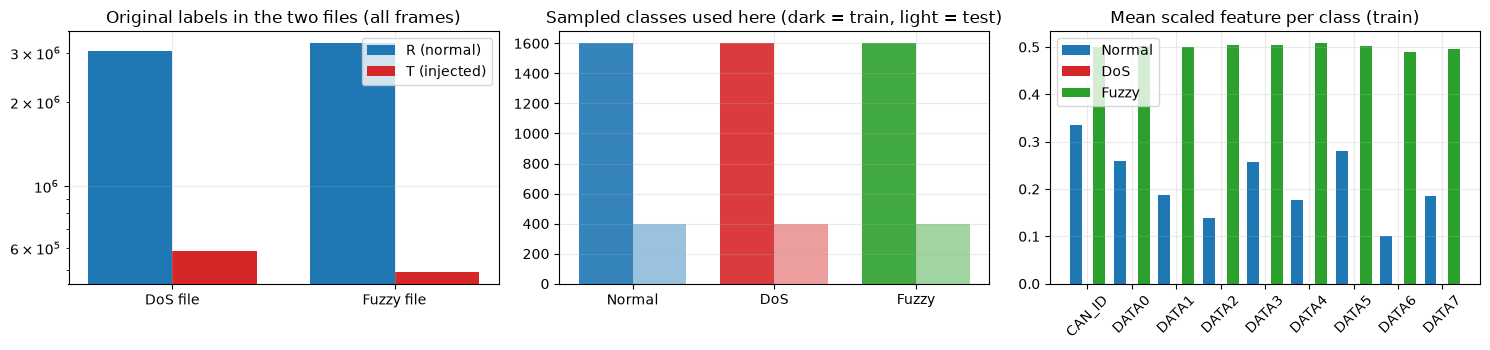

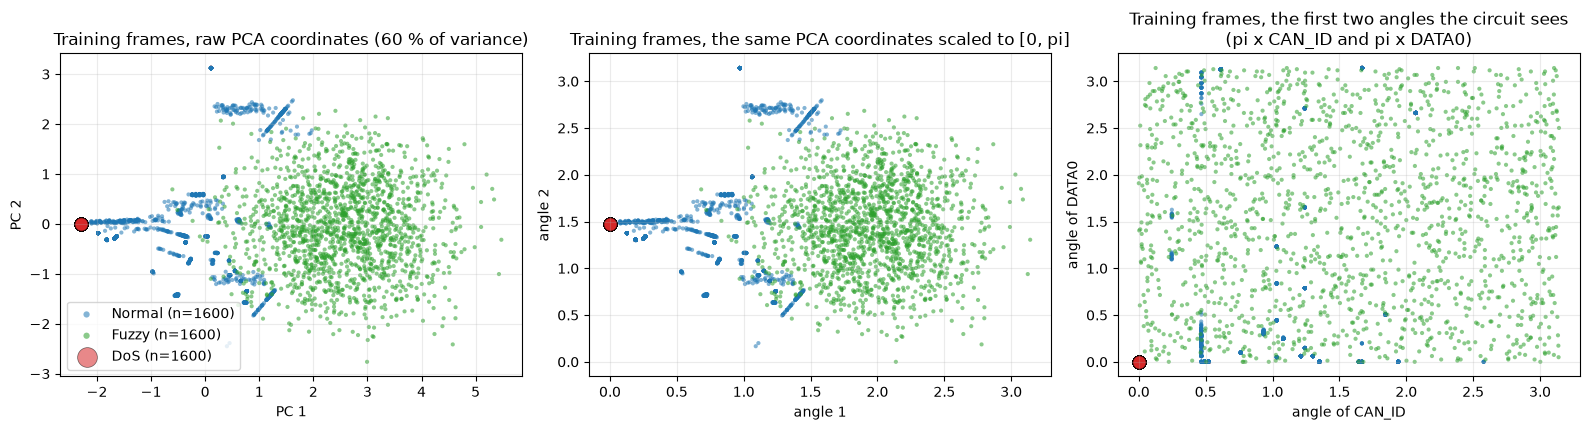

In [6]:
# ---- 1. shape, feature names, original labels and class counts ----
print("Original label values in the two HCRL files: 'R' = normal frame, 'T' = injected frame (DoS file: ID 0000 flood; Fuzzy file: random ID and payload)")
lab = pd.DataFrame({f.split("_")[0] + " file": {"R (normal)": int(r.normal_R), "T (injected)": int(r.injected_T), "total DLC-8 frames": int(r.frames_DLC8)}
                    for f, r in FILE_TABLE.set_index("file").iterrows()})
display(lab)
print("\nThis notebook (paper's three classes): 0 = Normal (R frames of both files), 1 = DoS (T frames of the DoS file), 2 = Fuzzy (T frames of the Fuzzy file)")
print("feature matrix  : train", D["Xtr_raw"].shape, "| test", D["Xte_raw"].shape, "(frames x 9 features)")
print("feature names   :", FEATURES, "(CAN ID as an integer 0..2047, data bytes 0..255)")
cnt = pd.DataFrame({"train": np.bincount(ytr, minlength=3), "test": np.bincount(yte, minlength=3)}, index=[f"{i} = {n}" for i, n in enumerate(CLASS_NAMES)])
display(cnt)
display(pd.DataFrame(D["Xtr_raw"], columns=FEATURES).groupby(pd.Series(ytr, name="class").map(dict(enumerate(CLASS_NAMES)))).agg(["mean"]).round(1).droplevel(1, axis=1))

# ---- 2. distribution of the real classes ----
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
x = np.arange(2); wd = .38
ax[0].bar(x - wd/2, [lab.loc["R (normal)", c] for c in lab.columns], wd, label="R (normal)", color="tab:blue")
ax[0].bar(x + wd/2, [lab.loc["T (injected)", c] for c in lab.columns], wd, label="T (injected)", color="tab:red")
ax[0].set_xticks(x); ax[0].set_xticklabels(lab.columns); ax[0].set_yscale("log"); ax[0].set_title("Original labels in the two files (all frames)"); ax[0].legend()
for i, (n, c) in enumerate(zip(CLASS_NAMES, CLASS_COLORS)):
    ax[1].bar(i - wd/2, np.sum(ytr == i), wd, color=c, alpha=.9); ax[1].bar(i + wd/2, np.sum(yte == i), wd, color=c, alpha=.45)
ax[1].set_xticks(range(3)); ax[1].set_xticklabels(CLASS_NAMES); ax[1].set_title("Sampled classes used here (dark = train, light = test)")
means = pd.DataFrame(D["Xtr"], columns=FEATURES).groupby(ytr).mean()
for i, (n, c) in enumerate(zip(CLASS_NAMES, CLASS_COLORS)):
    ax[2].bar(np.arange(9) + (i - 1) * .27, means.loc[i].values, .27, color=c, label=n)
ax[2].set_xticks(range(9)); ax[2].set_xticklabels(FEATURES, rotation=45); ax[2].set_title("Mean scaled feature per class (train)"); ax[2].legend()
plt.tight_layout(); plt.show()

# ---- 3. real frames in two dimensions, coloured by the ground-truth class (PCA fitted on the training split only) ----
std = StandardScaler().fit(D["Xtr_raw"]); pca = PCA(n_components=2, random_state=SEED).fit(std.transform(D["Xtr_raw"]))
Ptr = pca.transform(std.transform(D["Xtr_raw"]))
to_angle = MinMaxScaler((0, np.pi)).fit(Ptr)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
order = [0, 2, 1]                                  # draw Normal first, DoS (a single repeated point) last so that it stays visible
for c in order:
    m = ytr == c; big = 90 if c == 1 else 9
    ax[0].scatter(Ptr[m, 0], Ptr[m, 1], s=big, alpha=.55, color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (n={m.sum()})", edgecolor="k" if c == 1 else "none", linewidth=.5)
    A = to_angle.transform(Ptr[m])
    ax[1].scatter(A[:, 0], A[:, 1], s=big, alpha=.55, color=CLASS_COLORS[c], label=CLASS_NAMES[c], edgecolor="k" if c == 1 else "none", linewidth=.5)
    ax[2].scatter(np.pi * Xtr[m, 0], np.pi * Xtr[m, 1], s=big, alpha=.55, color=CLASS_COLORS[c], label=CLASS_NAMES[c], edgecolor="k" if c == 1 else "none", linewidth=.5)
ax[0].set_title(f"Training frames, raw PCA coordinates ({100*pca.explained_variance_ratio_.sum():.0f} % of variance)"); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2"); ax[0].legend(markerscale=1.5)
ax[1].set_title("Training frames, the same PCA coordinates scaled to [0, pi]"); ax[1].set_xlabel("angle 1"); ax[1].set_ylabel("angle 2")
ax[2].set_title("Training frames, the first two angles the circuit sees\n(pi x CAN_ID and pi x DATA0)"); ax[2].set_xlabel("angle of CAN_ID"); ax[2].set_ylabel("angle of DATA0")
plt.tight_layout(); plt.show()

Reading the plots: the DoS class is the single enlarged red point (all DoS frames are identical). Fuzzy frames (green) form a wide
cloud of random bytes and IDs; normal frames (blue) lie on thin lines and small clusters because real traffic repeats a few payload
patterns for each of 35 IDs. In the third panel the Fuzzy frames fill the whole square, whereas normal frames sit at a few discrete
CAN-ID angles (vertical stripes). Two PCA components summarise nine features only coarsely (60 % of the variance), so what is visible
here is a hint, not a proof, that the three classes are easy to separate.

## Quantum Circuit Architecture

Three gate-based quantum models are trained or evaluated in this notebook. This section defines each of them **twice**: as PennyLane
QNodes (these are the circuits that are drawn below) and inside a fast NumPy state-vector simulator that applies the same gates as small
matrices and is differentiated by `autograd` (PennyLane's tape machinery needs seconds per training step for a 9-qubit, 100-gate
circuit; the NumPy version needs milliseconds). A cell asserts that both give the same numbers to 1e-9, so the drawings show the circuits
that really run.

**1. QCAE (quantum convolutional autoencoder, 9 qubits, 84 trainable angles).** Each CAN feature, scaled to [0, 1], is angle-encoded with
`RY(pi x)` on its own qubit. Stage 1: *convolution* with a trainable 2-qubit block (RY, RY, CNOT, RZ, RY, CNOT, RY, RZ) on the pairs
(0,1) (2,3) (4,5) (6,7) and then (1,2) (3,4) (5,6) (7,8); *pooling*: qubits 1, 3, 5, 7 are discarded ("trash") after a controlled-RZ and a
controlled-RX from each trash qubit onto its kept neighbour. Stage 2: convolution on the five remaining qubits (0,2) (4,6) then (2,4) (6,8),
pooling of qubits 2 and 6. Three qubits (0, 4, 8) remain: the **latent code**. Training makes the six trash qubits end in |0>
(maximise P(all trash = 0), which is the fidelity of the reconstruction obtained by running the circuit backwards with fresh |0> trash
qubits). The latent features are <X>, <Y>, <Z> of the three latent qubits.

**2. QOC feature map (9 qubits, 19 trainable parameters).** The nine latent features (rescaled to [0, 1]) are encoded with `RY(gamma pi z)`;
then `2 x (RY(theta) on every qubit + CNOT ring)`, which only contains real gates and is therefore an **orthogonal** 512 x 512 matrix
(the "quantum orthogonal transformation with Pauli rotations"); then the features are encoded again with `RZ(gamma pi z)` (feature
expansion). The kernel is the state fidelity `k(a, b) = |<psi(a)|psi(b)>|^2`. The bandwidth `gamma` and the angles `theta` are trained by
maximising the centred kernel-target alignment on mini-batches of training frames.

**3. ZZ-type feature map (9 qubits, no trainable parameter)** of the plain QSVM baseline: two repetitions of Hadamards, `RZ(2x)` and
`IsingZZ` between neighbouring qubits (linear entanglement). It stands in for the paper's "QSVM" row, for which no circuit is given.

Assumptions where the paper omits circuit details are listed in the table "What follows the paper and what had to be chosen".

In [7]:
# ============ A fast exact state-vector simulator (NumPy + autograd) for the three circuits of this notebook ============
# PennyLane's default.qubit is exact too, but differentiating a 9-qubit, 100-gate circuit through PennyLane's tape machinery takes
# seconds per step. The simulator below applies the same gates as 2x2 / 4x4 matrices and lets `autograd` differentiate them, which is
# about 100 times faster. Every number it produces is checked against the PennyLane QNodes defined in the next cell.
NQ   = N_QUBITS_AE                                    # 9 wires
IDX  = np.arange(2 ** NQ)
BITS = ((IDX[:, None] >> (NQ - 1 - np.arange(NQ))) & 1).astype(float)    # bit of every basis state; wire 0 = most significant (PennyLane)
SIGN = 1.0 - 2.0 * BITS                                                   # Z eigenvalue (+1 for |0>, -1 for |1>)

def kron2(A, B):
    return anp.einsum("ij,kl->ikjl", A, B).reshape(A.shape[0] * B.shape[0], A.shape[1] * B.shape[1])

def mRY(t):
    c, s = anp.cos(t / 2), anp.sin(t / 2)
    return anp.stack([anp.stack([c, -s]), anp.stack([s, c])]) + 0j
def mRZ(t):
    a, b = anp.exp(-0.5j * t), anp.exp(0.5j * t)
    return anp.stack([anp.stack([a, 0 * a]), anp.stack([0 * a, b])])
def mRX(t):
    c, s = anp.cos(t / 2) + 0j, -1j * anp.sin(t / 2)
    return anp.stack([anp.stack([c, s]), anp.stack([s, c])])

CNOT_01 = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)   # control = first wire of the pair
CNOT_10 = np.array([[1, 0, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0], [0, 1, 0, 0]], dtype=complex)   # control = second wire of the pair
P0, P1, I2 = np.diag([1.0, 0.0]).astype(complex), np.diag([0.0, 1.0]).astype(complex), np.eye(2, dtype=complex)

def apply_gate(psi, U, wires):
    """psi: (B, 2, ..., 2) batch of states; U: (2^k, 2^k) matrix acting on `wires` (first wire = most significant)."""
    k = len(wires); axes = [w + 1 for w in wires]
    out = anp.tensordot(U.reshape((2,) * (2 * k)), psi, axes=(list(range(k, 2 * k)), axes))
    return anp.moveaxis(out, list(range(k)), axes)

def product_state_ry(a):
    """RY(a_i)|0> on every wire: amplitudes cos(a/2), sin(a/2); a has shape (B, NQ)."""
    c, s = anp.cos(a / 2), anp.sin(a / 2)
    amp = 1.0
    for i in range(NQ):                                                   # explicit product (anp.prod has no gradient where a factor is 0)
        amp = amp * (c[:, i][:, None] * (1.0 - BITS[:, i])[None, :] + s[:, i][:, None] * BITS[:, i][None, :])
    return amp + 0j                                                       # (B, 2^NQ)

# ------------------------------ 1. quantum convolutional autoencoder (QCAE) ------------------------------
# 9 wires, one per CAN feature. conv = trainable 2-qubit block on neighbouring wires, pool = trainable controlled rotations from the
# wire that is discarded (the "trash" wire) onto the wire that is kept. Training pushes all trash wires to |0>.
CONV_PAIRS = [(0, 1), (2, 3), (4, 5), (6, 7), (1, 2), (3, 4), (5, 6), (7, 8), (0, 2), (4, 6), (2, 4), (6, 8)]
POOL_PAIRS = [(1, 0), (3, 2), (5, 4), (7, 6), (2, 0), (6, 4)]                  # (discarded wire, kept wire)
STAGES     = [("conv", 0, 4), ("conv", 4, 8), ("pool", 0, 4), ("conv", 8, 10), ("conv", 10, 12), ("pool", 4, 6)]
TRASH, LATENT = [1, 3, 5, 7, 2, 6], [0, 4, 8]
N_CONV_W, N_POOL_W = 12 * 6, 6 * 2
N_PARAMS_QCAE = N_CONV_W + N_POOL_W                                            # 84 trainable angles

def block_unitary(w):
    g1 = kron2(mRY(w[0]), mRY(w[1])); g2 = kron2(mRZ(w[2]), mRY(w[3])); g3 = kron2(mRY(w[4]), mRZ(w[5]))
    return g3 @ CNOT_10 @ g2 @ CNOT_01 @ g1

def pool_unitary(w):                       # CRZ(w0) followed by CRX(w1), control = discarded wire, target = kept wire
    crz = kron2(P0, I2) + kron2(P1, mRZ(w[0]))
    crx = kron2(P0, I2) + kron2(P1, mRX(w[1]))
    return crx @ crz

def qcae_state(x, w):
    """x: (B, 9) features scaled to [0, 1] (angle encoding RY(pi x)); w: (84,) angles -> (B, 512) complex states."""
    B = x.shape[0]
    psi = product_state_ry(np.pi * np.asarray(x)).reshape((B,) + (2,) * NQ)
    cw, pw = w[:N_CONV_W].reshape(12, 6), w[N_CONV_W:].reshape(6, 2)
    for kind, lo, hi in STAGES:
        for k in range(lo, hi):
            psi = apply_gate(psi, block_unitary(cw[k]), CONV_PAIRS[k]) if kind == "conv" else apply_gate(psi, pool_unitary(pw[k]), POOL_PAIRS[k])
    return psi.reshape(B, -1)

TRASH_ZERO = (BITS[:, TRASH].sum(1) == 0).astype(float)                          # basis states with every trash wire in |0>
def prob_trash_zero(psi):
    return anp.sum((anp.real(psi) ** 2 + anp.imag(psi) ** 2) * TRASH_ZERO, axis=1)

FLIP = {q: IDX ^ (1 << (NQ - 1 - q)) for q in range(NQ)}
def latent_features(psi):
    """<X>, <Y>, <Z> of the three latent wires -> (B, 9). Order: X0 X4 X8 Y0 Y4 Y8 Z0 Z4 Z8 (same order as the QNode)."""
    p = np.abs(psi) ** 2; out = []
    for kind in "XYZ":
        for q in LATENT:
            if kind == "Z": out.append(p @ SIGN[:, q])
            elif kind == "X": out.append(np.sum(np.real(np.conj(psi) * psi[:, FLIP[q]]), axis=1))
            else: out.append(np.sum(np.real(np.conj(psi) * (-1j * SIGN[:, q])[None, :] * psi[:, FLIP[q]]), axis=1))
    return np.stack(out, axis=1)

# ------------------------------ 2. quantum orthogonal feature map (QOC) ------------------------------
# |psi(z)> = RZ(a) . [CNOT ring . RY(theta)]^L . RY(a) |0>,  a = gamma * pi * z,  z in [0, 1]^9.
# The block in the middle uses only RY rotations and CNOTs, so it is a REAL ORTHOGONAL 512 x 512 matrix; gamma and theta are trained.
def cnot_map(c, t): return IDX ^ (((IDX >> (NQ - 1 - c)) & 1) << (NQ - 1 - t))
RING_PERM = IDX.copy()
for _q in range(NQ): RING_PERM = RING_PERM[cnot_map(_q, (_q + 1) % NQ)]

def qoc_state(z01, p, layers=QOC_LAYERS):
    z01 = np.asarray(z01); B = z01.shape[0]
    gamma, theta = p[0], p[1:].reshape(layers, NQ)
    a = gamma * np.pi * z01
    psi = product_state_ry(a).reshape((B,) + (2,) * NQ)
    for l in range(layers):
        for q in range(NQ): psi = apply_gate(psi, mRY(theta[l, q]), [q])
        psi = psi.reshape(B, -1)[:, RING_PERM].reshape((B,) + (2,) * NQ)
    return psi.reshape(B, -1) * anp.exp(0.5j * anp.dot(a, -SIGN.T))              # RZ(a_i) on every wire = diagonal phase

# ------------------------------ 3. ZZ-type feature map of the plain QSVM baseline ------------------------------
HAD = np.array([[1, 1], [1, -1]]) / np.sqrt(2)
H_ALL = np.array([[1.0]])
for _ in range(NQ): H_ALL = np.kron(H_ALL, HAD)                                  # Hadamard on all 9 wires, 512 x 512
def zz_state(x01, reps=2):
    x = np.pi * np.asarray(x01); B = x.shape[0]
    psi = np.zeros((B, 2 ** NQ), dtype=complex); psi[:, 0] = 1.0
    zz = np.stack([(np.pi - x[:, i]) * (np.pi - x[:, i + 1]) for i in range(NQ - 1)], axis=1)       # linear entanglement
    pairs = np.stack([SIGN[:, i] * SIGN[:, i + 1] for i in range(NQ - 1)], axis=1)                 # (512, 8)
    for _ in range(reps):
        psi = psi @ H_ALL.T
        psi = psi * np.exp(-1j * (x @ SIGN.T + zz @ pairs.T))                                       # RZ(2x_i) and IsingZZ(2 (pi-x_i)(pi-x_j))
    return psi

def fidelity_kernel(PA, PB, chunk=500):
    """K_ij = |<psi_i|psi_j>|^2 from two sets of state vectors."""
    K = np.empty((len(PA), len(PB)))
    for i in range(0, len(PA), chunk):
        ov = PA[i:i + chunk] @ np.conj(PB).T
        K[i:i + chunk] = ov.real ** 2 + ov.imag ** 2
    return K
print("simulator ready: qubits", NQ, "| QCAE parameters", N_PARAMS_QCAE, "| QOC parameters", 1 + QOC_LAYERS * NQ)

simulator ready: qubits 9 | QCAE parameters 84 | QOC parameters 19


In [8]:
# ============ The same three circuits as PennyLane QNodes (these are what the drawings below show) ============
dev = qml.device("default.qubit", wires=NQ)

def qcae_ops(x, w):
    for i in range(NQ): qml.RY(np.pi * x[..., i], wires=i)                       # angle encoding of the 9 CAN features
    cw, pw = w[:N_CONV_W].reshape(12, 6), w[N_CONV_W:].reshape(6, 2)
    for kind, lo, hi in STAGES:
        for k in range(lo, hi):
            if kind == "conv":
                v, (a, b) = cw[k], CONV_PAIRS[k]
                qml.RY(v[0], wires=a); qml.RY(v[1], wires=b); qml.CNOT(wires=[a, b])
                qml.RZ(v[2], wires=a); qml.RY(v[3], wires=b); qml.CNOT(wires=[b, a])
                qml.RY(v[4], wires=a); qml.RZ(v[5], wires=b)
            else:
                v, (t, kp) = pw[k], POOL_PAIRS[k]
                qml.CRZ(v[0], wires=[t, kp]); qml.CRX(v[1], wires=[t, kp])

@qml.qnode(dev)
def qcae_probs(x, w):                       # training circuit: probability that every trash wire is |0>
    qcae_ops(x, w); return qml.probs(wires=TRASH)

@qml.qnode(dev)
def qcae_latent(x, w):                      # feature-extraction circuit: <X>, <Y>, <Z> of the three latent wires
    qcae_ops(x, w); return [qml.expval(op(q)) for op in (qml.PauliX, qml.PauliY, qml.PauliZ) for q in LATENT]

def qoc_ops(z01, p):
    gamma, theta = p[0], p[1:].reshape(QOC_LAYERS, NQ); a = gamma * np.pi * z01
    for i in range(NQ): qml.RY(a[..., i], wires=i)                               # angle encoding
    for l in range(QOC_LAYERS):
        for q in range(NQ): qml.RY(theta[l, q], wires=q)                         # orthogonal transformation (Pauli-Y rotations)
        for q in range(NQ): qml.CNOT(wires=[q, (q + 1) % NQ])                    # CNOT ring
    for i in range(NQ): qml.RZ(a[..., i], wires=i)                               # second encoding (feature expansion)

@qml.qnode(dev)
def qoc_circuit(z01, p):
    qoc_ops(z01, p); return qml.state()

def zz_ops(x01, reps=2):
    x = np.pi * x01
    for _ in range(reps):
        for i in range(NQ): qml.Hadamard(wires=i)
        for i in range(NQ): qml.RZ(2 * x[..., i], wires=i)
        for i in range(NQ - 1): qml.IsingZZ(2 * (np.pi - x[..., i]) * (np.pi - x[..., i + 1]), wires=[i, i + 1])

@qml.qnode(dev)
def zz_circuit(x01, reps=2):
    zz_ops(x01, reps); return qml.state()

# ---- equivalence check: simulator == PennyLane QNode on real, scaled CAN frames and random parameters ----
chk = np.random.default_rng(0)
xs = Xtr[chk.choice(len(Xtr), 6, replace=False)]
w_chk = chk.normal(0, 1.0, N_PARAMS_QCAE); p_chk = np.r_[1.3, chk.normal(0, 1.0, QOC_LAYERS * NQ)]
st = qcae_state(xs, w_chk)
assert np.allclose(np.stack(qcae_latent(xs, w_chk), axis=1), latent_features(st), atol=1e-9), "latent features differ"
assert np.allclose(qcae_probs(xs, w_chk)[:, 0], prob_trash_zero(st), atol=1e-9), "trash probability differs"
assert np.allclose(qoc_circuit(xs, p_chk), qoc_state(xs, p_chk), atol=1e-9), "QOC state differs"
assert np.allclose(zz_circuit(xs), zz_state(xs), atol=1e-9), "ZZ state differs"
print("OK: the fast simulator reproduces the PennyLane QNodes (QCAE latent features, trash probability, QOC state, ZZ state) to 1e-9")

OK: the fast simulator reproduces the PennyLane QNodes (QCAE latent features, trash probability, QOC state, ZZ state) to 1e-9


### The QCAE circuit that is executed

The drawing is the PennyLane QNode `qcae_probs` (the training circuit) on one real, scaled CAN frame with random demonstration angles.
The first column is the `RY` angle encoding, then come the convolution blocks and the controlled-rotation pooling gates; the probability
distribution of the six trash wires (1, 3, 5, 7, 2, 6) is measured at the end.

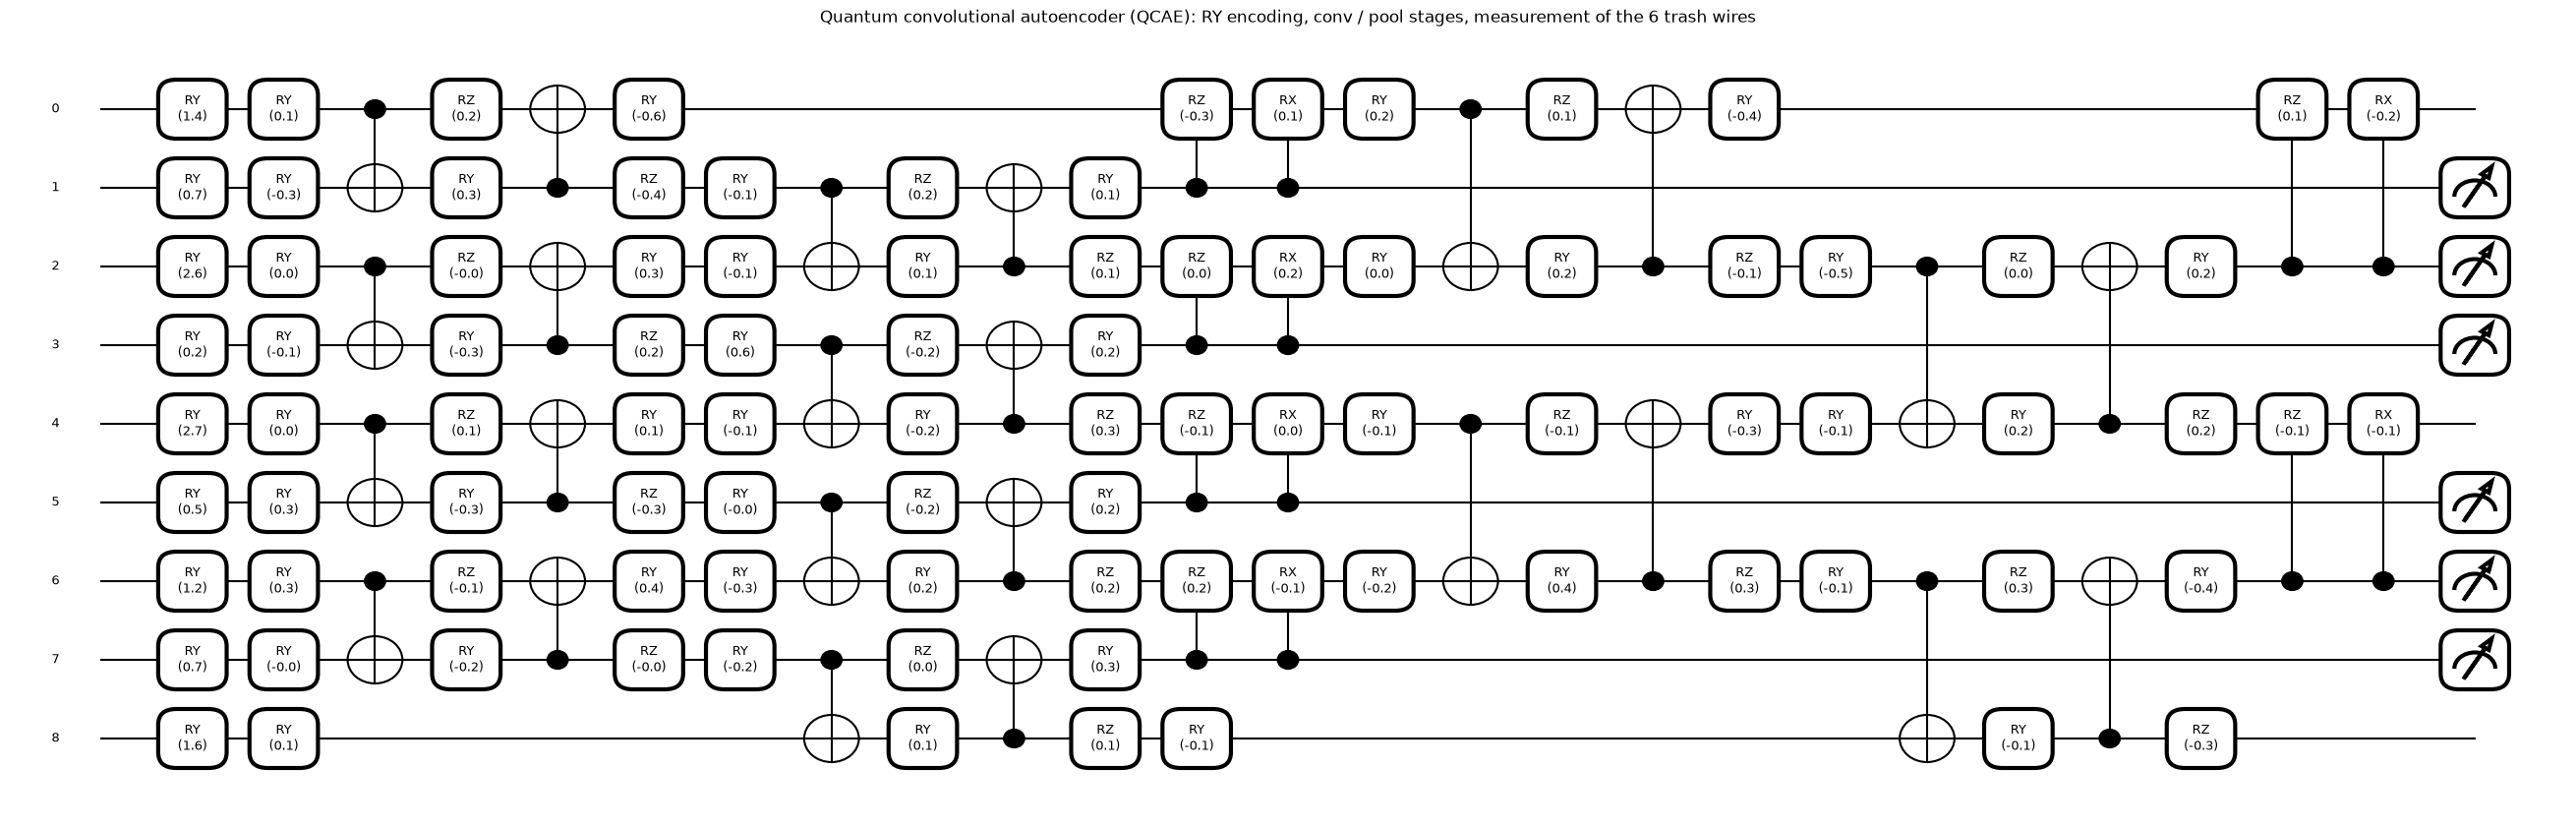

In [9]:
# -- facts of the executed circuits (qubits, depth, trainable parameters) --
def circuit_facts(name, qnode, args, n_trainable):
    sp = qml.specs(qnode)(*args)
    res = sp.resources if hasattr(sp, "resources") else sp["resources"]
    depth = res.depth if hasattr(res, "depth") else res["depth"]
    ngates = res.num_gates if hasattr(res, "num_gates") else res["num_gates"]
    gt = res.gate_types if hasattr(res, "gate_types") else res["gate_types"]
    return dict(circuit=name, qubits=NQ, depth=int(depth), gates=int(ngates), trainable_parameters=n_trainable, gate_types=dict(gt))

x0 = Xtr[0]                                                   # one real, scaled CAN frame
w_demo = np.random.default_rng(SEED).normal(0, 0.3, N_PARAMS_QCAE)
p_demo = np.r_[1.0, np.random.default_rng(SEED).normal(0, 0.5, QOC_LAYERS * NQ)]
z_demo = (latent_features(qcae_state(x0[None], w_demo))[0] + 1.0) / 2.0     # a real latent vector in [0, 1]

fig, ax = qml.draw_mpl(qcae_probs, decimals=1, fontsize=9)(x0, w_demo)
ax.set_title("Quantum convolutional autoencoder (QCAE): RY encoding, conv / pool stages, measurement of the 6 trash wires", fontsize=12)
fig.set_size_inches(26, 8); plt.show()

### The QOC and ZZ circuits, and the numbers that describe all three

Both circuits end in the full state vector, from which the fidelity kernel is computed (the kernel is the squared overlap of two such
states, evaluated exactly from the state vectors, so no extra circuit is needed per pair of frames).

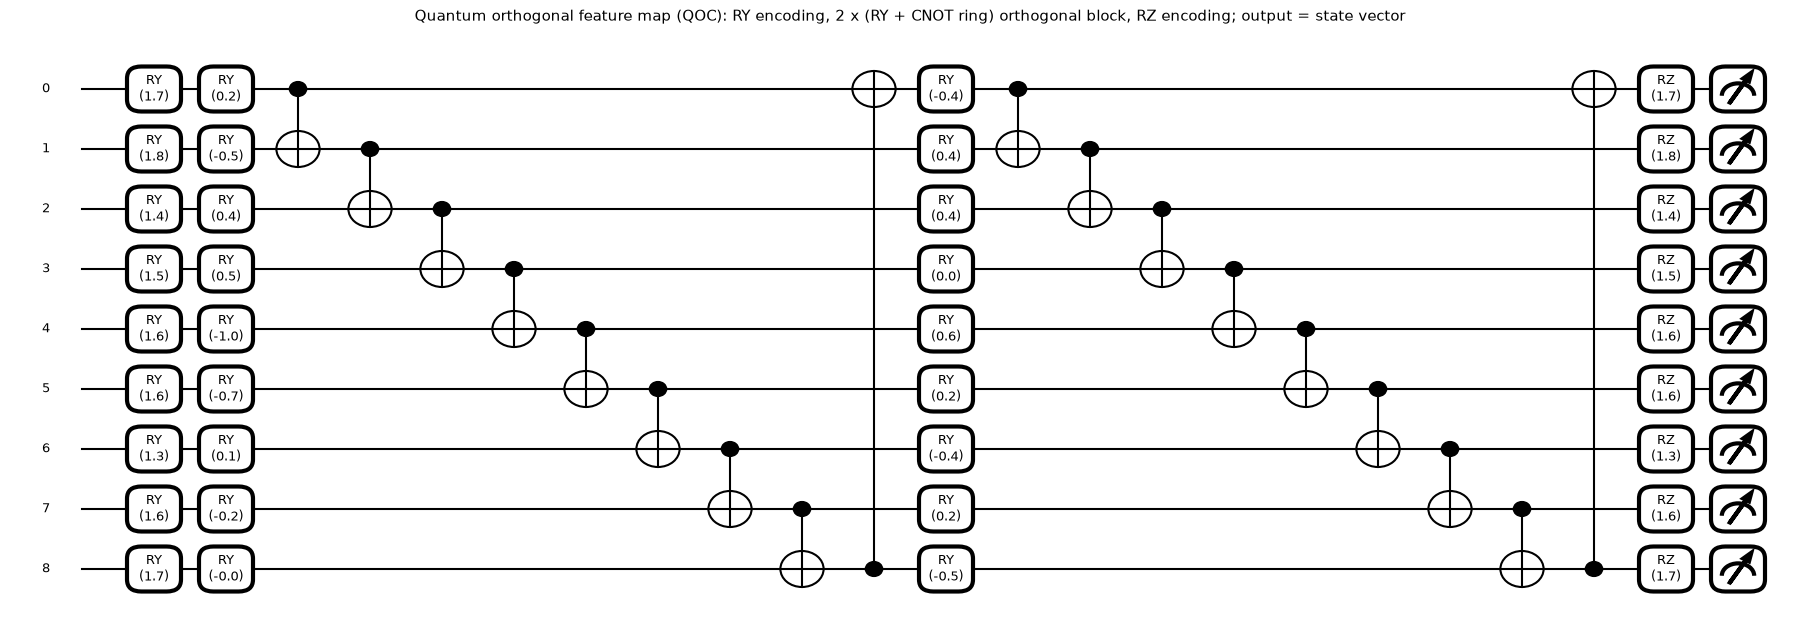

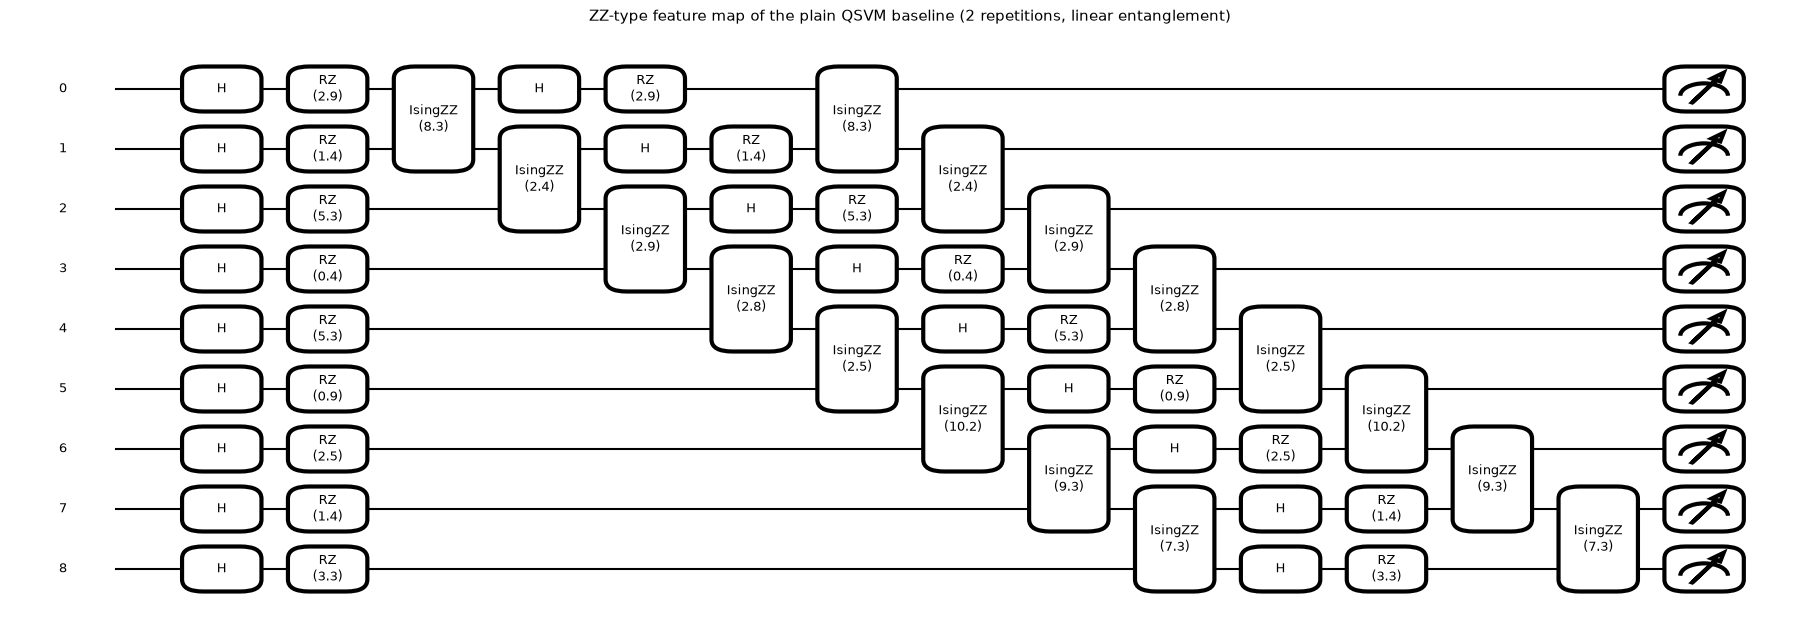

,circuit,qubits,depth,gates,trainable_parameters
0,QCAE (training circuit),9,25,117,84
1,QOC feature map,9,22,54,19
2,ZZ feature map (QSVM baseline),9,14,52,0


QCAE (training circuit) -> {'RY': 57, 'CNOT': 24, 'RZ': 24, 'CRZ': 6, 'CRX': 6}
QOC feature map -> {'RY': 27, 'CNOT': 18, 'RZ': 9}
ZZ feature map (QSVM baseline) -> {'Hadamard': 18, 'RZ': 18, 'IsingZZ': 16}
Measurements: QCAE = probability that all 6 trash wires are |0> (training) and <X>,<Y>,<Z> of the 3 latent wires (features); QOC and ZZ = full state vector, used to build the fidelity kernel |<psi(a)|psi(b)>|^2.


In [10]:
fig, ax = qml.draw_mpl(qoc_circuit, decimals=1, fontsize=9)(z_demo, p_demo)
ax.set_title(f"Quantum orthogonal feature map (QOC): RY encoding, {QOC_LAYERS} x (RY + CNOT ring) orthogonal block, RZ encoding; output = state vector", fontsize=11)
fig.set_size_inches(18, 6); plt.show()

fig, ax = qml.draw_mpl(zz_circuit, decimals=1, fontsize=9)(x0)
ax.set_title("ZZ-type feature map of the plain QSVM baseline (2 repetitions, linear entanglement)", fontsize=11)
fig.set_size_inches(18, 6); plt.show()

facts = [circuit_facts("QCAE (training circuit)", qcae_probs, (x0, w_demo), N_PARAMS_QCAE),
         circuit_facts("QOC feature map", qoc_circuit, (z_demo, p_demo), 1 + QOC_LAYERS * NQ),
         circuit_facts("ZZ feature map (QSVM baseline)", zz_circuit, (x0,), 0)]
ft = pd.DataFrame(facts)
display(ft.drop(columns="gate_types"))
for f in facts: print(f["circuit"], "->", f["gate_types"])
print("Measurements: QCAE = probability that all 6 trash wires are |0> (training) and <X>,<Y>,<Z> of the 3 latent wires (features);"
      " QOC and ZZ = full state vector, used to build the fidelity kernel |<psi(a)|psi(b)>|^2.")

### Training and evaluation helpers

The next cell defines the functions that the rest of the notebook uses: metrics, a small Adam optimiser, the classical model zoo, the
QCAE training and encoding, the kernel-target-alignment training of the QOC feature map, the SVM on a precomputed quantum kernel, and a
`run_pipeline(seed)` function that repeats the whole experiment for another seed. Results are collected in `RESULTS[seed]`.

In [11]:
from autograd import value_and_grad
from sklearn.base import clone

METRIC_COLS = ["Acc", "Precision", "Recall", "F1"]
def metrics(y, p):
    """Accuracy in %, macro-averaged precision / recall / F1 (the paper does not say how it averaged; classes are balanced here)."""
    return dict(Acc=100 * accuracy_score(y, p), Precision=precision_score(y, p, average="macro", zero_division=0),
                Recall=recall_score(y, p, average="macro", zero_division=0), F1=f1_score(y, p, average="macro", zero_division=0))

RESULTS, PRED = {}, {}                 # RESULTS[seed] = list of rows; PRED[(seed, model)] = test predictions
def record(seed, model, group, yte, pred, seconds, **extra):
    RESULTS.setdefault(seed, []).append(dict(model=model, group=group, **metrics(yte, pred), seconds=round(seconds, 1), **extra))
    PRED[(seed, model)] = np.asarray(pred)

def adam_run(vg, p, steps, lr, sample, every=10, tag=""):
    """Plain Adam on a function returning (value, gradient); `sample()` yields the arguments of each mini-batch step."""
    m, v, hist = np.zeros_like(p), np.zeros_like(p), []
    for t in range(1, steps + 1):
        val, g = vg(p, *sample())
        m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g * g
        p = p - lr * (m / (1 - 0.9 ** t)) / (np.sqrt(v / (1 - 0.999 ** t)) + 1e-8)
        hist.append(float(val))
        if every and (t % every == 0 or t == 1): print(f"  {tag} step {t:4d}/{steps}  loss {np.mean(hist[-every:]):.4f}", flush=True)
    return p, hist

# ---------------------------------- stage 1: classical models on the raw (scaled) CAN features ----------------------------------
def classical_zoo(seed):
    return {"SVM (RBF)": SVC(kernel="rbf", C=10, gamma="scale"),                       # CHOICE: C = 10 (paper: not given)
            "Random Forest": RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=2),
            "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
            "Naive Bayes": GaussianNB(),
            "XGBoost": XGBClassifier(n_estimators=100, max_depth=4, random_state=seed, n_jobs=2, verbosity=0),
            "MLP (64-32)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=400, random_state=seed)}

def stage_classical(D, A_tr, A_te, group, names=None, prefix=""):
    seed = D["seed"]
    for name, clf in classical_zoo(seed).items():
        if names and name not in names: continue
        t0 = time.time(); clf.fit(A_tr, D["ytr"]); pred = clf.predict(A_te)
        record(seed, prefix + name, group, D["yte"], pred, time.time() - t0)

# ---------------------------------- stage 2: the quantum convolutional autoencoder ----------------------------------
def train_qcae(Xtr, seed, steps=None, batch=None, verbose=True):
    steps, batch = steps or QCAE_STEPS, batch or QCAE_BATCH
    r = np.random.default_rng(seed)
    w0 = r.normal(0, 0.3, N_PARAMS_QCAE)                                               # CHOICE: initial angles ~ N(0, 0.3)
    loss = lambda w, xb: 1.0 - anp.mean(prob_trash_zero(qcae_state(xb, w)))              # 1 - P(all trash wires in |0>)
    sample = lambda: (Xtr[r.choice(len(Xtr), min(batch, len(Xtr)), replace=False)],)
    t0 = time.time()
    w, hist = adam_run(value_and_grad(loss), w0, steps, QCAE_LR, sample, every=10 if verbose else 0, tag="QCAE")
    return w0, w, hist, time.time() - t0

def qcae_encode(X, w, chunk=1500):
    """Latent features (B, 9) and per-frame probability that all trash wires are |0> (= reconstruction fidelity)."""
    Z, F = [], []
    for i in range(0, len(X), chunk):
        st = qcae_state(X[i:i + chunk], w); Z.append(latent_features(st)); F.append(np.asarray(prob_trash_zero(st)))
    return np.vstack(Z), np.concatenate(F)

def stage_qcae(D, verbose=True):
    w0, w, hist, t = train_qcae(D["Xtr"], D["seed"], verbose=verbose)
    Ztr, Ftr = qcae_encode(D["Xtr"], w); Zte, Fte = qcae_encode(D["Xte"], w)
    _, Fte0 = qcae_encode(D["Xte"], w0)
    return dict(w0=w0, w=w, hist=hist, seconds=t, Ztr=Ztr, Zte=Zte, Ftr=Ftr, Fte=Fte, Fte_untrained=Fte0)

# ---------------------------------- SVM on a precomputed quantum kernel ----------------------------------
def svc_on_kernel(Ktr, ytr, Kte, seed):
    """Choose C on a validation part of the TRAINING split, refit on the whole training split, predict the test split."""
    itr, iva = train_test_split(np.arange(len(ytr)), test_size=VAL_FRAC, stratify=ytr, random_state=seed)
    best = None
    for C in C_GRID:
        acc = SVC(kernel="precomputed", C=C).fit(Ktr[np.ix_(itr, itr)], ytr[itr]).score(Ktr[np.ix_(iva, itr)], ytr[iva])
        if best is None or acc > best[0]: best = (acc, C)
    clf = SVC(kernel="precomputed", C=best[1]).fit(Ktr, ytr)
    return clf.predict(Kte), best[1], best[0], clf

# ---------------------------------- stage 3: the quantum orthogonal classifier (QOC) ----------------------------------
def centred_alignment_loss(K, same):
    """Negative centred kernel-target alignment between the quantum kernel and the ideal 'same class' kernel."""
    B = K.shape[0]; H = np.eye(B) - 1.0 / B
    T = H @ (2.0 * same - 1.0) @ H
    Kc = anp.dot(anp.dot(H, K), H)
    return -anp.sum(Kc * T) / (anp.sqrt(anp.sum(Kc * Kc)) * np.sqrt(np.sum(T * T)) + 1e-12)

def train_qoc(A_tr, ytr, seed, steps=None, batch=None, verbose=True):
    steps, batch = steps or QOC_STEPS, batch or QOC_BATCH
    r = np.random.default_rng(seed + 1)
    p0 = np.r_[1.0, r.normal(0, 0.5, QOC_LAYERS * NQ)]                                    # CHOICE: gamma = 1, theta ~ N(0, 0.5)
    def loss(p, zb, same):
        ps = qoc_state(zb, p); ov = anp.dot(ps, anp.conj(ps).T)
        return centred_alignment_loss(anp.real(ov) ** 2 + anp.imag(ov) ** 2, same)
    def sample():
        b = r.choice(len(A_tr), min(batch, len(A_tr)), replace=False)
        return A_tr[b], (ytr[b][:, None] == ytr[b][None, :]).astype(float)
    t0 = time.time()
    p, hist = adam_run(value_and_grad(loss), p0, steps, QOC_LR, sample, every=10 if verbose else 0, tag="QOC")
    return p0, p, hist, time.time() - t0

def stage_qoc(D, A_tr, A_te, model, group, verbose=True):
    seed = D["seed"]; ytr, yte = D["ytr"], D["yte"]
    p0, p, hist, t_train = train_qoc(A_tr, ytr, seed, verbose=verbose)
    t0 = time.time()
    Ptr, Pte = qoc_state(A_tr, p), qoc_state(A_te, p)
    Ktr, Kte = fidelity_kernel(Ptr, Ptr), fidelity_kernel(Pte, Ptr); t_kernel = time.time() - t0
    t0 = time.time(); pred, C, val_acc, clf = svc_on_kernel(Ktr, ytr, Kte, seed); t_svm = time.time() - t0
    record(seed, model, group, yte, pred, t_train + t_kernel + t_svm, C=C, val_acc=round(100 * val_acc, 2))
    return dict(p0=p0, p=p, hist=hist, Ktr=Ktr, Kte=Kte, C=C, seconds=(t_train, t_kernel, t_svm))

def stage_zz(D, model="QSVM (ZZ feature map, raw)", group="quantum, raw features"):
    seed = D["seed"]; ytr, yte = D["ytr"], D["yte"]
    t0 = time.time(); Ptr, Pte = zz_state(D["Xtr"]), zz_state(D["Xte"])
    Ktr, Kte = fidelity_kernel(Ptr, Ptr), fidelity_kernel(Pte, Ptr)
    pred, C, val_acc, clf = svc_on_kernel(Ktr, ytr, Kte, seed)
    record(seed, model, group, yte, pred, time.time() - t0, C=C, val_acc=round(100 * val_acc, 2))
    return dict(Ktr=Ktr, Kte=Kte, C=C)

# ---------------------------------- the whole pipeline for one seed (used for the extra seeds) ----------------------------------
LAT01 = lambda Z: (Z + 1.0) / 2.0              # latent <.> values in [-1, 1] -> angles/features in [0, 1]
def run_pipeline(seed, verbose=False):
    D = prepare(seed)
    stage_classical(D, D["Xtr"], D["Xte"], "classical, raw features")
    QC = stage_qcae(D, verbose=verbose)
    stage_classical(D, QC["Ztr"], QC["Zte"], "classical, QCAE latent", names=["SVM (RBF)", "Random Forest"], prefix="QCAE + ")
    stage_zz(D)
    stage_qoc(D, D["Xtr"], D["Xte"], "QOC-SVM (raw features, no QCAE)", "quantum, raw features", verbose=verbose)
    out = stage_qoc(D, LAT01(QC["Ztr"]), LAT01(QC["Zte"]), "QCAE + QOC-SVM (paper)", "hybrid quantum", verbose=verbose)
    RESULTS[seed][-1]["ae_fidelity_test"] = round(float(QC["Fte"].mean()), 4)
    return D

## 3. Classical reference models on the same inputs

Before looking at the quantum models, the usual classical models are trained on the **same nine scaled features** (and, later, on the
same quantum latent code). They show how hard the task really is. Hyper-parameters are fixed in advance (`# CHOICE:` in the helper
cell), not tuned on the test split.

In [12]:
stage_classical(D, Xtr, Xte, "classical, raw features")
res0 = pd.DataFrame(RESULTS[SEED]); display(res0[["model", "group", "Acc", "Precision", "Recall", "F1", "seconds"]].round(4))

,model,group,Acc,Precision,Recall,F1,seconds
0,SVM (RBF),"classical, raw features",99.7500,0.9975,0.9975,0.9975,1.3
1,Random Forest,"classical, raw features",100.0000,1.0000,1.0000,1.0000,6.1
2,KNN (k=5),"classical, raw features",98.9167,0.9895,0.9892,0.9892,0.9
3,Naive Bayes,"classical, raw features",95.4167,0.9542,0.9542,0.9542,0.1
4,XGBoost,"classical, raw features",100.0000,1.0000,1.0000,1.0000,33.0
5,MLP (64-32),"classical, raw features",99.6667,0.9967,0.9967,0.9967,48.5


## 4. Training the quantum convolutional autoencoder

The autoencoder is trained **without labels** on mini-batches of training frames (all three classes). The loss is `1 - P(all six trash
qubits in |0>)`, averaged over the batch. The curve shows the loss; the histogram shows, per class, the fidelity of the trained
autoencoder on the **test** frames (how well a frame survives being compressed from nine qubits to three and decompressed again).
The third part of the output shows the nine-dimensional latent code of the training frames, projected to two dimensions, coloured by the real class.

  QCAE step    1/100  loss 0.6758


  QCAE step   10/100  loss 0.5618


  QCAE step   20/100  loss 0.5292


  QCAE step   30/100  loss 0.5288


  QCAE step   40/100  loss 0.5210


...

  QCAE step   70/100  loss 0.5124


  QCAE step   80/100  loss 0.5002


  QCAE step   90/100  loss 0.5073


  QCAE step  100/100  loss 0.5049



QCAE trained in 173 s | trash-wires-in-|0> probability (= reconstruction fidelity) on the TEST frames: untrained 0.346 -> trained 0.504


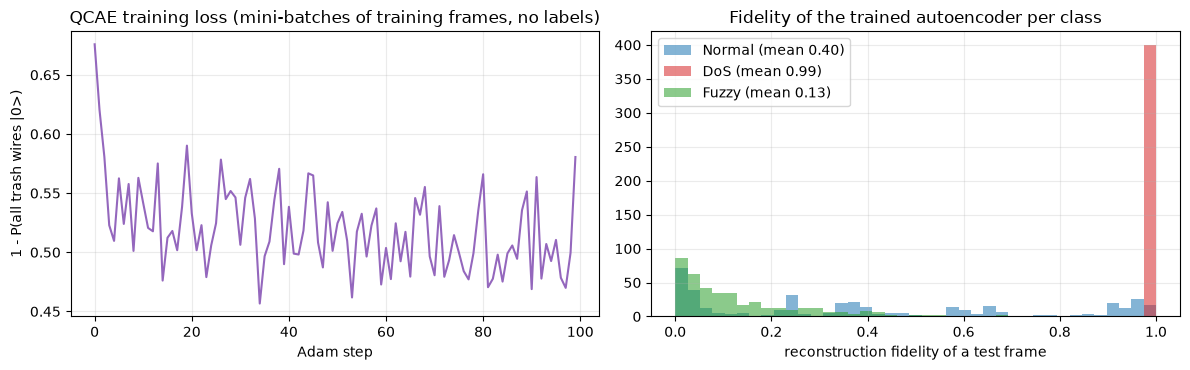

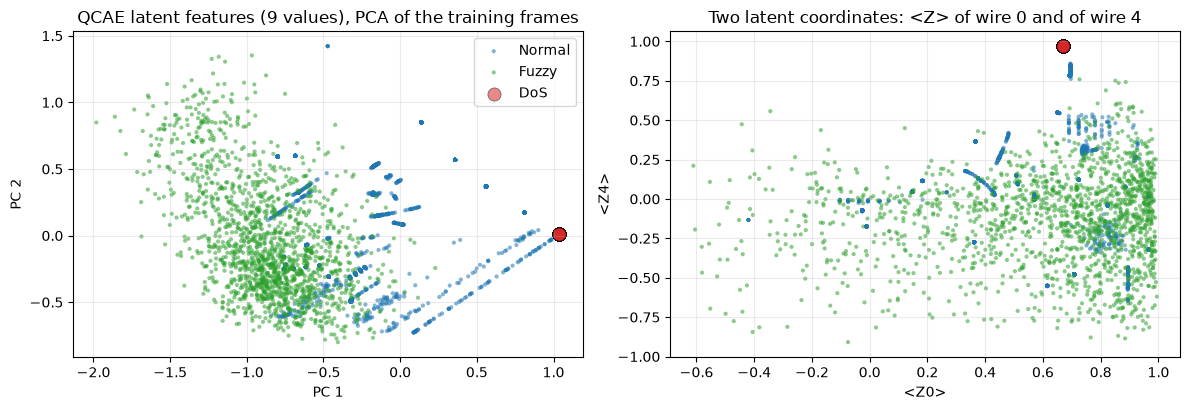

In [13]:
QC = stage_qcae(D)
print(f"\nQCAE trained in {QC['seconds']:.0f} s | trash-wires-in-|0> probability (= reconstruction fidelity) on the TEST frames: "
      f"untrained {QC['Fte_untrained'].mean():.3f} -> trained {QC['Fte'].mean():.3f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(QC["hist"], color="tab:purple"); ax[0].set_xlabel("Adam step"); ax[0].set_ylabel("1 - P(all trash wires |0>)")
ax[0].set_title("QCAE training loss (mini-batches of training frames, no labels)")
bins = np.linspace(0, 1, 40)
for c in range(3):
    ax[1].hist(QC["Fte"][yte == c], bins=bins, alpha=.55, color=CLASS_COLORS[c], label=f"{CLASS_NAMES[c]} (mean {QC['Fte'][yte == c].mean():.2f})")
ax[1].set_xlabel("reconstruction fidelity of a test frame"); ax[1].set_title("Fidelity of the trained autoencoder per class"); ax[1].legend()
plt.tight_layout(); plt.show()

# latent space: real test frames coloured by ground truth
Zp = PCA(n_components=2, random_state=SEED).fit(QC["Ztr"])
Ltr = Zp.transform(QC["Ztr"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for c in [0, 2, 1]:
    m = ytr == c; big = 90 if c == 1 else 9
    ax[0].scatter(Ltr[m, 0], Ltr[m, 1], s=big, alpha=.55, color=CLASS_COLORS[c], label=CLASS_NAMES[c], edgecolor="k" if c == 1 else "none", linewidth=.5)
    ax[1].scatter(QC["Ztr"][m, 6], QC["Ztr"][m, 7], s=big, alpha=.55, color=CLASS_COLORS[c], label=CLASS_NAMES[c], edgecolor="k" if c == 1 else "none", linewidth=.5)
ax[0].set_title("QCAE latent features (9 values), PCA of the training frames"); ax[0].set_xlabel("PC 1"); ax[0].set_ylabel("PC 2"); ax[0].legend()
ax[1].set_title("Two latent coordinates: <Z> of wire 0 and of wire 4"); ax[1].set_xlabel("<Z0>"); ax[1].set_ylabel("<Z4>")
plt.tight_layout(); plt.show()

**What the autoencoder learned.** The trained circuit compresses some frames almost perfectly and others hardly at all, and the fidelity
histogram shows that this per-frame fidelity already separates the classes: the all-zero DoS frames have fidelity close to 1 (an
all-zero pattern is the easiest thing for the circuit to compress), the random Fuzzy frames are close to 0, and normal traffic lies in
between. In other words the *reconstruction error* of the autoencoder is itself an attack indicator, which is the idea behind using autoencoders
for anomaly detection; the paper does not use it, it classifies the latent code instead. In the latent-space plots every DoS frame is one point,
normal frames lie on thin curves and Fuzzy frames form a diffuse cloud that overlaps them.

In [14]:
# the same classical models (the two strongest simple ones) on the 9 QCAE latent features instead of the 9 raw features
stage_classical(D, QC["Ztr"], QC["Zte"], "classical, QCAE latent", names=["SVM (RBF)", "Random Forest"], prefix="QCAE + ")
res0 = pd.DataFrame(RESULTS[SEED]); display(res0[res0.group == "classical, QCAE latent"][["model", "group", "Acc", "Precision", "Recall", "F1", "seconds"]].round(4))

,model,group,Acc,Precision,Recall,F1,seconds
6,QCAE + SVM (RBF),"classical, QCAE latent",96.8333,0.9690,0.9683,0.9683,0.4
7,QCAE + Random Forest,"classical, QCAE latent",99.4167,0.9942,0.9942,0.9942,2.6


## 5. Quantum kernels and the quantum orthogonal classifier

Three quantum kernels are compared, all built from exact state vectors and all fed to the same `SVC(kernel="precomputed")`:

* **QSVM with a ZZ feature map** on the raw scaled frames (the paper's "QSVM" row),
* **QOC-SVM on the raw frames** (the QOC feature map without the autoencoder; an ablation),
* **QCAE + QOC-SVM** (the paper's model): QOC feature map on the nine QCAE latent features.

The orthogonal feature maps are trained with kernel-target alignment (no test data involved); `C` is then chosen on a validation part of
the training split. The kernel matrices are drawn for 120 training frames per class, sorted by class: a good kernel shows three bright
blocks on the diagonal.

  QOC step    1/60  loss -0.6204


  QOC step   10/60  loss -0.6754


  QOC step   20/60  loss -0.6815


  QOC step   30/60  loss -0.6923


  QOC step   40/60  loss -0.6679


...

  QOC step   30/60  loss -0.6671


  QOC step   40/60  loss -0.6542


  QOC step   50/60  loss -0.6763


  QOC step   60/60  loss -0.6739


QOC feature map trained: bandwidth gamma 1.00 -> 1.52 | chosen SVM C = 10.0 | train / kernel / SVM seconds = 59 / 23 / 5


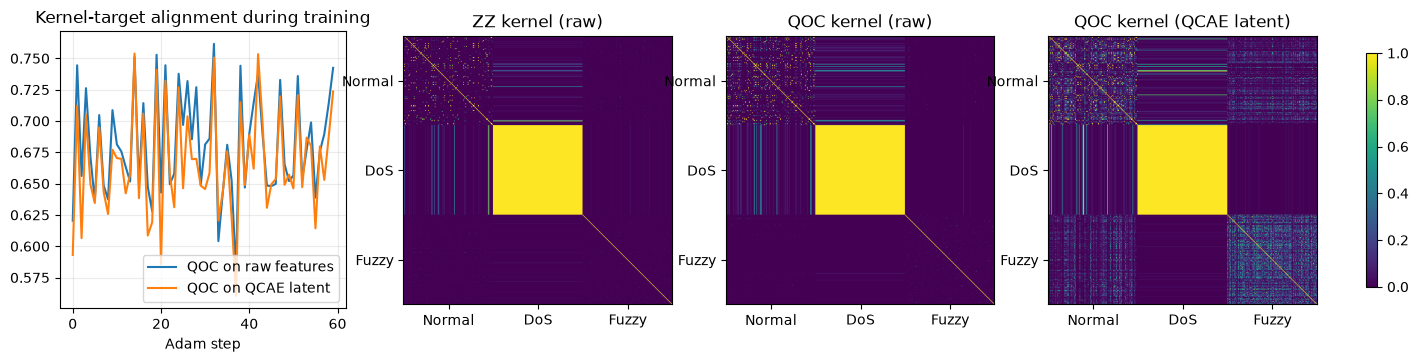

In [15]:
ZZ = stage_zz(D)
QOC_RAW = stage_qoc(D, Xtr, Xte, "QOC-SVM (raw features, no QCAE)", "quantum, raw features")
Atr_lat, Ate_lat = LAT01(QC["Ztr"]), LAT01(QC["Zte"])
QOC = stage_qoc(D, Atr_lat, Ate_lat, "QCAE + QOC-SVM (paper)", "hybrid quantum")
RESULTS[SEED][-1]["ae_fidelity_test"] = round(float(QC["Fte"].mean()), 4)
print(f"QOC feature map trained: bandwidth gamma {QOC['p0'][0]:.2f} -> {QOC['p'][0]:.2f} | chosen SVM C = {QOC['C']} | "
      f"train / kernel / SVM seconds = " + " / ".join(f"{t:.0f}" for t in QOC["seconds"]))

fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
ax[0].plot(-np.array(QOC_RAW["hist"]), label="QOC on raw features"); ax[0].plot(-np.array(QOC["hist"]), label="QOC on QCAE latent")
ax[0].set_title("Kernel-target alignment during training"); ax[0].set_xlabel("Adam step"); ax[0].legend()
sel = np.concatenate([np.flatnonzero(ytr == c)[:120] for c in range(3)])          # 120 training frames per class, sorted by class
for a, (nm, K) in zip(ax[1:], [("ZZ kernel (raw)", ZZ["Ktr"]), ("QOC kernel (raw)", QOC_RAW["Ktr"]), ("QOC kernel (QCAE latent)", QOC["Ktr"])]):
    im = a.imshow(K[np.ix_(sel, sel)], vmin=0, vmax=1, cmap="viridis"); a.set_title(nm); a.grid(False)
    a.set_xticks([60, 180, 300]); a.set_xticklabels(CLASS_NAMES); a.set_yticks([60, 180, 300]); a.set_yticklabels(CLASS_NAMES)
plt.colorbar(im, ax=ax[1:], fraction=.012); plt.show()

**Reading the kernels.** The ZZ kernel and the QOC kernel on raw frames show three blocks: all DoS frames are identical, so their block
is one solid yellow square (kernel value 1); normal frames resemble each other only partly; and the Fuzzy block is almost completely
dark apart from its diagonal, i.e. two different random Fuzzy frames are nearly orthogonal in the 512-dimensional Hilbert space
(the well-known *kernel concentration* of fidelity kernels in many qubits). The SVM therefore recognises a Fuzzy frame as "not similar to
anything from Normal or DoS" rather than as "similar to other Fuzzy frames". On the latent code (right) the Fuzzy block is brighter: the
autoencoder maps random frames to a more regular region. The left plot is the training signal of the orthogonal feature map (kernel-target alignment of each
mini-batch): it fluctuates between about 0.6 and 0.75 with at most a small upward trend, because every step uses a different
mini-batch and the learning rate was not tuned, so it should not be over-read; the bandwidth gamma printed above did move away from its start value.

## 6. All models side by side

Accuracy, macro-averaged precision / recall / F1 on the held-out test frames and wall-clock seconds (training + prediction, QCAE
training included for the hybrid rows). Then the confusion matrices of the key models and, because the aim is attack detection, the
binary view with "attack" (DoS or Fuzzy) as the positive class.

,model,group,Acc,Precision,Recall,F1,seconds
0,Random Forest,"classical, raw features",100.0000,1.0000,1.0000,1.0000,6.1
1,XGBoost,"classical, raw features",100.0000,1.0000,1.0000,1.0000,33.0
2,"QOC-SVM (raw features, no QCAE)","quantum, raw features",99.9167,0.9992,0.9992,0.9992,50.8
3,SVM (RBF),"classical, raw features",99.7500,0.9975,0.9975,0.9975,1.3
4,"QSVM (ZZ feature map, raw)","quantum, raw features",99.7500,0.9975,0.9975,0.9975,18.5
5,MLP (64-32),"classical, raw features",99.6667,0.9967,0.9967,0.9967,48.5
6,QCAE + Random Forest,"classical, QCAE latent",99.4167,0.9942,0.9942,0.9942,2.6
7,KNN (k=5),"classical, raw features",98.9167,0.9895,0.9892,0.9892,0.9
8,QCAE + QOC-SVM (paper),hybrid quantum,98.9167,0.9893,0.9892,0.9892,86.3
9,QCAE + SVM (RBF),"classical, QCAE latent",96.8333,0.9690,0.9683,0.9683,0.4


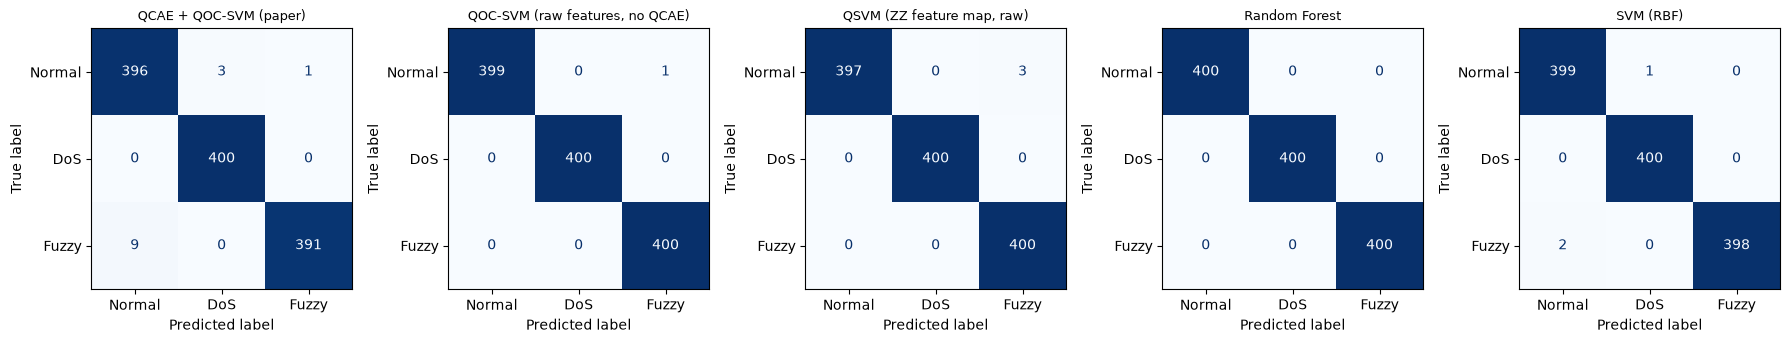

,model,TP,FN,FP,TN,attack_recall,false_alarm_rate
0,QCAE + QOC-SVM (paper),791,9,4,396,0.9888,0.0100
1,"QOC-SVM (raw features, no QCAE)",800,0,1,399,1.0000,0.0025
2,"QSVM (ZZ feature map, raw)",800,0,3,397,1.0000,0.0075
3,Random Forest,800,0,0,400,1.0000,0.0000
4,SVM (RBF),798,2,1,399,0.9975,0.0025


In [16]:
res0 = pd.DataFrame(RESULTS[SEED])
display(res0[["model", "group", "Acc", "Precision", "Recall", "F1", "seconds"]].sort_values("F1", ascending=False).round(4).reset_index(drop=True))

show = ["QCAE + QOC-SVM (paper)", "QOC-SVM (raw features, no QCAE)", "QSVM (ZZ feature map, raw)", "Random Forest", "SVM (RBF)"]
fig, ax = plt.subplots(1, len(show), figsize=(3.6 * len(show), 3.6))
for a, nm in zip(ax, show):
    ConfusionMatrixDisplay(confusion_matrix(yte, PRED[(SEED, nm)]), display_labels=CLASS_NAMES).plot(ax=a, colorbar=False, cmap="Blues")
    a.set_title(nm, fontsize=9); a.grid(False)
plt.tight_layout(); plt.show()

# attack (DoS or Fuzzy) as the positive class
rows = []
for nm in show:
    cm = confusion_matrix(yte > 0, PRED[(SEED, nm)] > 0)
    tn, fp, fn, tp = cm.ravel(); rows.append(dict(model=nm, TP=tp, FN=fn, FP=fp, TN=tn, attack_recall=round(tp / (tp + fn), 4), false_alarm_rate=round(fp / (fp + tn), 4)))
display(pd.DataFrame(rows))

## 7. More seeds, the paper's Table 1 and Fig. 4

The whole pipeline (sampling, split, QCAE, QOC, all baselines) is repeated for the extra seeds listed in the configuration cell
(`EXTRA_SEEDS`; empty in `FAST_MODE`). The table reports mean and standard deviation over seeds; with a single seed the standard
deviation is not defined. Then the paper's Table 1 rows that this notebook can reproduce are put next to the notebook's numbers, and
Fig. 4 (F1 by model family) is drawn again.

In [17]:
for sd in EXTRA_SEEDS:
    t0 = time.time(); run_pipeline(sd, verbose=False); print(f"seed {sd} done in {time.time() - t0:.0f} s", flush=True)
allrows = pd.DataFrame([dict(seed=s, **r) for s, rows in RESULTS.items() for r in rows])
agg = allrows.groupby(["model", "group"], sort=False)[METRIC_COLS + ["seconds"]].agg(["mean", "std"]).round(4)
agg.columns = [f"{a}_{b}" for a, b in agg.columns]
SUMMARY = agg.reset_index().sort_values("F1_mean", ascending=False).reset_index(drop=True)
print(f"seeds used: {sorted(RESULTS)} (std is NaN with a single seed)")
display(SUMMARY)

seed 43 done in 720 s


seed 44 done in 825 s


seeds used: [42, 43, 44] (std is NaN with a single seed)


,model,group,Acc_mean,Acc_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1_mean,F1_std,seconds_mean,seconds_std
0,Random Forest,"classical, raw features",100.0000,0.0000,1.0000,0.0000,1.0000,0.0000,1.0000,0.0000,6.2000,2.7514
1,"QOC-SVM (raw features, no QCAE)","quantum, raw features",99.9722,0.0481,0.9997,0.0005,0.9997,0.0005,0.9997,0.0005,153.5333,92.3347
2,XGBoost,"classical, raw features",99.9167,0.0833,0.9992,0.0008,0.9992,0.0008,0.9992,0.0008,31.1333,18.1720
3,SVM (RBF),"classical, raw features",99.8333,0.1443,0.9983,0.0014,0.9983,0.0014,0.9983,0.0014,0.9000,0.4000
4,MLP (64-32),"classical, raw features",99.7222,0.0962,0.9972,0.0010,0.9972,0.0010,0.9972,0.0010,32.3333,16.0026
5,"QSVM (ZZ feature map, raw)","quantum, raw features",99.6389,0.0962,0.9964,0.0009,0.9964,0.0010,0.9964,0.0010,39.3333,20.9510
6,QCAE + Random Forest,"classical, QCAE latent",99.6389,0.2097,0.9964,0.0021,0.9964,0.0021,0.9964,0.0021,4.3000,1.5133
7,KNN (k=5),"classical, raw features",99.3333,0.4167,0.9935,0.0040,0.9933,0.0042,0.9933,0.0042,0.5667,0.3512
8,QCAE + QOC-SVM (paper),hybrid quantum,98.9167,0.0833,0.9893,0.0008,0.9892,0.0008,0.9892,0.0008,153.6333,61.6794
9,QCAE + SVM (RBF),"classical, QCAE latent",97.2500,0.7217,0.9728,0.0073,0.9725,0.0072,0.9725,0.0072,2.0667,1.4468


,model,paper_name,paper_acc,notebook_acc,gap_acc,paper_F1,notebook_F1,gap_F1
0,SVM (RBF),SVM,84.31,99.83,15.52,0.840,0.9983,0.1583
1,Random Forest,RF,88.95,100.00,11.05,0.890,1.0000,0.1100
2,KNN (k=5),KNN,94.05,99.33,5.28,0.940,0.9933,0.0533
3,Naive Bayes,Naive Bayes,94.31,95.69,1.38,0.940,0.9569,0.0169
4,XGBoost,XGB,91.00,99.92,8.92,0.910,0.9992,0.0892
5,MLP (64-32),MLP,93.80,99.72,5.92,0.929,0.9972,0.0682
6,"QSVM (ZZ feature map, raw)",QSVM,97.80,99.64,1.84,0.965,0.9964,0.0314
7,QCAE + QOC-SVM (paper),QCAE + QOC-SVM,99.43,98.92,-0.51,0.994,0.9892,-0.0048


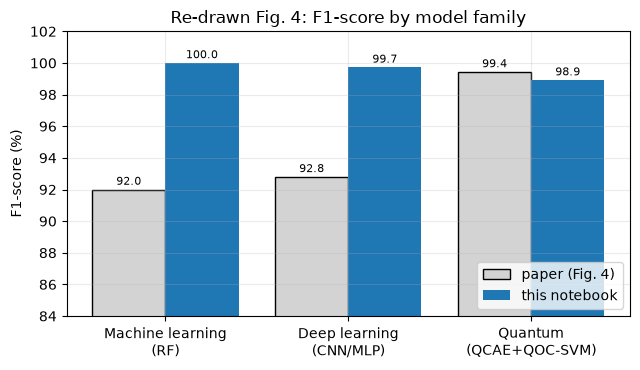

In [18]:
# ---- Table 1 of the paper next to this notebook (mean over seeds) ----
mean = allrows.groupby("model")[METRIC_COLS].mean()
map_to_paper = {"SVM (RBF)": "SVM", "Random Forest": "RF", "KNN (k=5)": "KNN", "Naive Bayes": "Naive Bayes", "XGBoost": "XGB", "MLP (64-32)": "MLP",
                "QSVM (ZZ feature map, raw)": "QSVM", "QCAE + QOC-SVM (paper)": "QCAE + QOC-SVM"}
t1 = []
for nm, pk in map_to_paper.items():
    pa, pp, pr, pf = PAPER_TABLE1[pk]; m = mean.loc[nm]
    t1.append(dict(model=nm, paper_name=pk, paper_acc=pa, notebook_acc=round(m.Acc, 2), gap_acc=round(m.Acc - pa, 2),
                   paper_F1=pf, notebook_F1=round(m.F1, 4), gap_F1=round(m.F1 - pf, 4)))
T1 = pd.DataFrame(t1); display(T1)

# ---- Fig. 4 of the paper: F1 of the ML, DL and quantum model ----
ml_best = mean.loc[["SVM (RBF)", "Random Forest", "KNN (k=5)", "Naive Bayes", "XGBoost"], "F1"].max()
fig, ax = plt.subplots(figsize=(6.5, 3.8))
labels = ["Machine learning\n(RF)", "Deep learning\n(CNN/MLP)", "Quantum\n(QCAE+QOC-SVM)"]
paper_f1 = [92.00, 92.80, 99.43]; mine = [100 * mean.loc["Random Forest", "F1"], 100 * mean.loc["MLP (64-32)", "F1"], 100 * mean.loc["QCAE + QOC-SVM (paper)", "F1"]]
xx = np.arange(3)
ax.bar(xx - .2, paper_f1, .4, label="paper (Fig. 4)", color="lightgray", edgecolor="k"); ax.bar(xx + .2, mine, .4, label="this notebook", color="tab:blue")
for i, (a, b) in enumerate(zip(paper_f1, mine)): ax.text(i - .2, a + .3, f"{a:.1f}", ha="center", fontsize=8); ax.text(i + .2, b + .3, f"{b:.1f}", ha="center", fontsize=8)
ax.set_xticks(xx); ax.set_xticklabels(labels); ax.set_ylabel("F1-score (%)"); ax.set_ylim(max(0, min(paper_f1 + mine) - 8), 102); ax.legend(loc="lower right"); ax.set_title("Re-drawn Fig. 4: F1-score by model family")
plt.tight_layout(); plt.show()

## 8. The learning curve (Fig. 5 of the paper)

The paper shows accuracy, precision, recall and F1 growing smoothly while the model sees more training batches. The closest honest
re-drawing is a learning curve: the SVM on the (already trained) quantum kernel is refitted on growing, stratified fractions of the training split
and evaluated on the same test split. A Random Forest on the raw frames is added for comparison. (The QCAE and the QOC angles were
trained once on the full training split; only the SVM is refitted.)

,train_frames,QCAE+QOC Acc,QCAE+QOC Precision,QCAE+QOC Recall,QCAE+QOC F1,RF Acc,RF Precision,RF Recall,RF F1
0,240,92.7500,0.9282,0.9275,0.9273,99.3333,0.9935,0.9933,0.9933
1,747,96.5000,0.9670,0.9650,0.9649,99.9167,0.9992,0.9992,0.9992
2,1253,97.5833,0.9761,0.9758,0.9758,100.0000,1.0000,1.0000,1.0000
3,1760,98.0000,0.9805,0.9800,0.9800,99.9167,0.9992,0.9992,0.9992
4,2267,98.4167,0.9844,0.9842,0.9842,99.9167,0.9992,0.9992,0.9992
5,2773,98.5833,0.9861,0.9858,0.9858,100.0000,1.0000,1.0000,1.0000
6,3280,98.9167,0.9893,0.9892,0.9892,99.9167,0.9992,0.9992,0.9992
7,3787,98.9167,0.9893,0.9892,0.9892,100.0000,1.0000,1.0000,1.0000
8,4293,98.9167,0.9893,0.9892,0.9892,100.0000,1.0000,1.0000,1.0000
9,4800,98.9167,0.9893,0.9892,0.9892,100.0000,1.0000,1.0000,1.0000


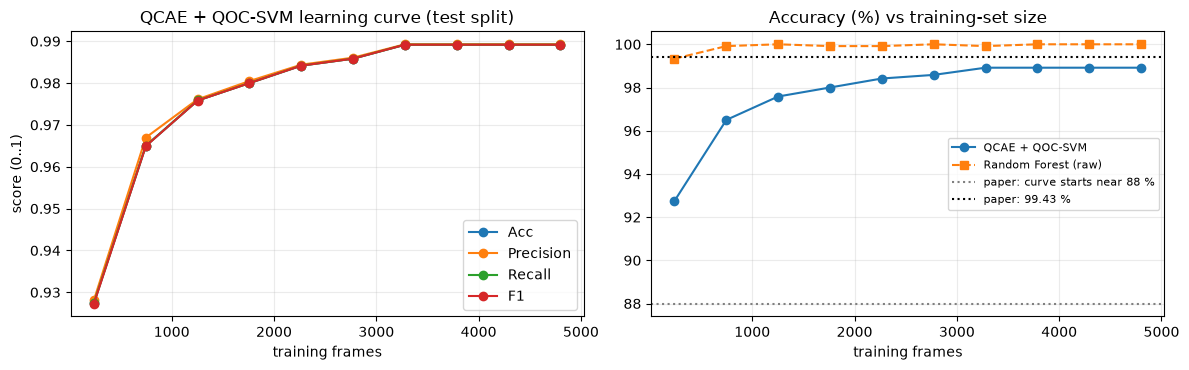

In [19]:
# ---- Fig. 5 of the paper: learning curve of QCAE + QOC-SVM (accuracy / precision / recall / F1 on the test split vs training-set size) ----
fracs = np.linspace(0.05, 1.0, CURVE_POINTS)
rc = np.random.default_rng(SEED + 7)
rows = []
for f in fracs:
    n_sub = max(30, int(round(f * len(ytr))))
    sub, _ = train_test_split(np.arange(len(ytr)), train_size=n_sub, stratify=ytr, random_state=int(rc.integers(1e6))) if n_sub < len(ytr) else (np.arange(len(ytr)), None)
    clf = SVC(kernel="precomputed", C=QOC["C"]).fit(QOC["Ktr"][np.ix_(sub, sub)], ytr[sub])
    pq = clf.predict(QOC["Kte"][:, sub]); mq = metrics(yte, pq)
    rf = RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=2).fit(Xtr[sub], ytr[sub]); mr = metrics(yte, rf.predict(Xte))
    rows.append(dict(train_frames=len(sub), **{f"QCAE+QOC {k}": v for k, v in mq.items()}, **{f"RF {k}": v for k, v in mr.items()}))
CURVE = pd.DataFrame(rows); display(CURVE.round(4))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for k, c in zip(METRIC_COLS, ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
    y_ = CURVE[f"QCAE+QOC {k}"] / (100 if k == "Acc" else 1)
    ax[0].plot(CURVE.train_frames, y_, "o-", color=c, label=k)
ax[0].set_title("QCAE + QOC-SVM learning curve (test split)"); ax[0].set_xlabel("training frames"); ax[0].set_ylabel("score (0..1)"); ax[0].legend()
ax[1].plot(CURVE.train_frames, CURVE["QCAE+QOC Acc"], "o-", label="QCAE + QOC-SVM"); ax[1].plot(CURVE.train_frames, CURVE["RF Acc"], "s--", label="Random Forest (raw)")
ax[1].axhline(PAPER_CURVE_START_ACC, color="gray", ls=":", label="paper: curve starts near 88 %"); ax[1].axhline(PAPER_CURVE_END_ACC, color="k", ls=":", label="paper: 99.43 %")
ax[1].set_title("Accuracy (%) vs training-set size"); ax[1].set_xlabel("training frames"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9. Paper versus this notebook: one verdict per claim

Rule used for numbers: **reproduced** if the notebook is within 2 accuracy points (or 0.02 for precision / recall / F1) of the paper,
**exceeded** if it is higher by more than that, **not reached** if lower by more than that; **cannot be checked** when the paper gives
too little information or the data are not public.

In [20]:
# ---- side-by-side comparison with the paper: one verdict per checkable claim ----
q = mean.loc["QCAE + QOC-SVM (paper)"]
def num_verdict(paper, mine, tol):
    gap = mine - paper
    return ("reproduced" if abs(gap) <= tol else ("exceeded" if gap > 0 else "not reached")), gap

rows = []
def add(claim, paper, mine, tol=None, verdict=None, note=""):
    if tol is not None:
        verdict, gap = num_verdict(paper, mine, tol); note = (f"gap {gap:+.4f}; " + note).strip("; ")
    rows.append(dict(claim=claim, paper=paper, notebook=mine if isinstance(mine, str) else round(float(mine), 4), verdict=verdict, note=note))

add("QCAE + QOC-SVM accuracy (%)", 99.43, q.Acc, tol=2.0, note=f"{len(RESULTS)} seed(s)")
add("QCAE + QOC-SVM precision", 0.991, q.Precision, tol=0.02)
add("QCAE + QOC-SVM recall", 0.989, q.Recall, tol=0.02)
add("QCAE + QOC-SVM F1-score", 0.994, q.F1, tol=0.02)
others = mean.drop(index="QCAE + QOC-SVM (paper)")
best_other = others.F1.idxmax()
add("QCAE + QOC-SVM has the highest F1 of all models", "yes (Table 1)", f"F1 {q.F1:.4f} vs best other {best_other} {others.F1.max():.4f}",
    verdict="reproduced" if q.F1 >= others.F1.max() - 1e-9 else "not reached",
    note="every model here is evaluated on the same frames and the same 9 features")
add("Hybrid beats the plain QSVM (paper 97.80 %)", "99.43 > 97.80", f"{q.Acc:.2f} vs {mean.loc['QSVM (ZZ feature map, raw)', 'Acc']:.2f}",
    verdict="reproduced" if q.Acc > mean.loc["QSVM (ZZ feature map, raw)", "Acc"] else "not reached")
add("The QCAE stage helps the QOC-SVM", "implied by the hybrid design", f"{q.Acc:.2f} with vs {mean.loc['QOC-SVM (raw features, no QCAE)', 'Acc']:.2f} without QCAE",
    verdict="reproduced" if q.Acc > mean.loc["QOC-SVM (raw features, no QCAE)", "Acc"] + 0.5 else "not reached",
    note="ablation: same QOC feature map on the raw angle-encoded frames")
for nm, pk in [("Random Forest", "RF"), ("SVM (RBF)", "SVM")]:
    add(f"Classical {pk} accuracy is only {PAPER_TABLE1[pk][0]} % (Table 1)", PAPER_TABLE1[pk][0], mean.loc[nm, "Acc"], tol=2.0,
        note="classical baselines on these three classes are much stronger than in the paper" if mean.loc[nm, "Acc"] > PAPER_TABLE1[pk][0] + 2 else "")
add("Learning curve starts near 88 % accuracy", PAPER_CURVE_START_ACC, CURVE["QCAE+QOC Acc"].iloc[0], tol=2.0, note=f"smallest training set = {CURVE.train_frames.iloc[0]} frames")
add("Learning curve rises steadily to the final accuracy", "monotone rise 88 -> 99.43", f"{CURVE['QCAE+QOC Acc'].iloc[0]:.1f} -> {CURVE['QCAE+QOC Acc'].iloc[-1]:.1f}",
    verdict="reproduced" if (np.diff(CURVE["QCAE+QOC Acc"].values) >= -1.0).all() and CURVE["QCAE+QOC Acc"].iloc[-1] > CURVE["QCAE+QOC Acc"].iloc[0] + 2 else "not reached",
    note="rise of more than 2 points with no drop larger than 1 point")
add("Optimal 'batches : batch size' = 7741 : 31", "7741:31", "n/a", verdict="cannot be checked",
    note="7741 x 31 = 239,971, i.e. about 80 % of 300,000 frames: it only describes the training-set size, not a tunable hyper-parameter")
add("Own CARLA 0.9.14 dataset (300,000 frames in total)", "300,000", f"{len(ytr) + len(yte):,} frames of the public data", verdict="cannot be checked",
    note="'Data will be made available on request'; this notebook uses the public HCRL Car-Hacking DoS and Fuzzy files only")
add("QAE, VQC, QKNN, QAE+QRF, QAE+QKNN baselines of Table 1", "97.30 / 91.05 / 82.61 / 93.26 / 94.98", "not implemented", verdict="cannot be checked",
    note="the paper gives no circuits or hyper-parameters for them")
VERDICTS = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 90): display(VERDICTS)
print(VERDICTS.verdict.value_counts().to_string())

,claim,paper,notebook,verdict,note
0,QCAE + QOC-SVM accuracy (%),99.43,98.9167,reproduced,gap -0.5133; 3 seed(s)
1,QCAE + QOC-SVM precision,0.991,0.9893,reproduced,gap -0.0017
2,QCAE + QOC-SVM recall,0.989,0.9892,reproduced,gap +0.0002
3,QCAE + QOC-SVM F1-score,0.994,0.9892,reproduced,gap -0.0048
4,QCAE + QOC-SVM has the highest F1 of all models,yes (Table 1),F1 0.9892 vs best other Random Forest 1.0000,not reached,every model here is evaluated on the same frames and the same 9 features
5,Hybrid beats the plain QSVM (paper 97.80 %),99.43 > 97.80,98.92 vs 99.64,not reached,
6,The QCAE stage helps the QOC-SVM,implied by the hybrid design,98.92 with vs 99.97 without QCAE,not reached,ablation: same QOC feature map on the raw angle-encoded frames
7,Classical RF accuracy is only 88.95 % (Table 1),88.95,100.0,exceeded,gap +11.0500; classical baselines on these three classes are much stronger than in the...
8,Classical SVM accuracy is only 84.31 % (Table 1),84.31,99.8333,exceeded,gap +15.5233; classical baselines on these three classes are much stronger than in the...
9,Learning curve starts near 88 % accuracy,88.0,92.75,exceeded,gap +4.7500; smallest training set = 240 frames


verdict
reproduced           5
not reached          3
exceeded             3
cannot be checked    3


## 10. Reading the paper critically

The numbers of this notebook change slightly between seeds and between `FAST_MODE` and the full run, so the points below are
phrased in terms of what the tables above show, not of one exact value.

1. **The task is easy, and the paper's classical baselines look weak.** Every DoS frame is identical (ID `0000`, zero payload), and Fuzzy
   frames carry a random ID and random bytes while normal traffic uses 35 fixed IDs with repetitive payloads. Classical models on the
   same nine features (section 6) are already close to perfect here, far above the paper's Random Forest (88.95 %) and SVM
   (84.31 %). Either the paper's classical models were trained very differently (different features, label noise, the CARLA data) or
   they were not tuned; the paper does not say.
2. **No quantum advantage can be read from the result.** The plain ZZ-kernel QSVM and the QOC-SVM without any autoencoder score about the
   same as the full QCAE + QOC-SVM (the ablation rows in section 6 show whether the autoencoder helped), and a classical Random Forest or
   XGBoost is at least as good. The claim "the hybrid beats classical ML, DL and QML" is therefore not supported by this data; at best the
   hybrid is competitive with, and a point or two below or above, the other quantum kernels. All circuits are tiny (9 qubits) and simulated exactly,
   so there is also no statement about hardware, noise, shot noise or speed.
3. **The autoencoder compresses poorly by construction.** The nine features are angle-encoded on nine separate qubits, which gives a
   *product state*: there is no correlation between qubits for the autoencoder to exploit, and the trash qubits can be emptied only
   partly (mean fidelity far from 1 in section 4). The latent code keeps less information than the raw frames, and a classical SVM on
   the latent code is indeed worse than on the raw frames. The useful signal is rather the per-frame reconstruction fidelity.
4. **Fidelity kernels on random data concentrate.** Section 5 shows that two different Fuzzy frames have an almost zero kernel value,
   so the quantum SVM detects Fuzzy frames mainly because they resemble nothing else. That works here only because the Fuzzy attack is
   *maximally random*; a smarter attacker who replays or slightly modifies normal frames would look much more like Normal.
5. **Random frame-level splits overstate generalisation.** CAN traffic repeats itself: all DoS test frames and a large share of the
   normal test frames also occur verbatim in the training split (printed in section 2). A realistic IDS must work on streams, with
   timing and sequence features and a split in time (or by driving session); the paper's ten attributes contain no timestamp.
6. **Table 1 is internally inconsistent.** An F1-score cannot exceed the harmonic mean of the corresponding precision and recall in a
   binary problem, and in the multi-class case a macro-F1 stays close to it: for QAE the paper lists precision 0.97, recall 0.93, F1 0.972
   (harmonic mean 0.950), and for the proposed model precision 0.991 and recall 0.989 give 0.990, not 0.994. The averaging over the three classes
   is never stated.
7. **Fig. 5 and the "7741:31 batches" claim cannot be reproduced as described.** An SVM on a quantum kernel is not trained in batches;
   7741 x 31 = 239,971 is simply 80 % of 300,000 frames. The curve in section 8 is the nearest honest equivalent (the SVM refitted on
   growing training sets): it rises quickly and then flattens, and it starts higher than the paper's 88 %.
8. **Reproducibility.** The method section gives no qubit count, no circuit parameters, no optimiser, no seed and no SVM penalty; QPCA
   and amplitude encoding are named but not described; the CARLA data "will be made available on request". Everything marked
   `# CHOICE:` in the code is a decision the reader has to make, and different decisions can move the hybrid model by a point or two.

## 11. Exercises

1. **Time split.** Replace the random split by a split in time (train on the first 80 % of each file in time order, test on the last
   20 %) and keep the nine features. Does the ranking of the models change? How many test frames are now exact duplicates of training frames?
2. **Add timing.** Add the inter-arrival time of frames with the same ID as a tenth feature (see the QBoost notebook in this folder for
   how it is computed) and use ten qubits. Which models profit, and does the DoS class stay a single point?
3. **Train the autoencoder on normal traffic only.** In `train_qcae` use only training frames of class 0 and use the trash probability
   of a frame as an anomaly score. How well does that single number detect DoS and Fuzzy frames (ROC AUC)? Compare with Isolation Forest.
4. **A smaller latent space.** Change `LATENT` / `TRASH` so that only two qubits remain (the pooling stages must be adapted) and
   plot how accuracy of `QCAE + SVM (RBF)` falls with the size of the bottleneck.
5. **Amplitude encoding.** Implement the amplitude-encoded kernel mentioned in the paper (normalise the nine latent values and load them
   into four qubits with `qml.AmplitudeEmbedding`), compute its fidelity kernel and compare it with the angle-encoded QOC kernel.